# Basketline Supermarkets: Grocery Demand Planning and Forecasting

**Analysing daily store sales to understand demand patterns, measure promotion effectiveness and build a forecast that drives replenishment.**

| | |
|---|---|
| **Tool** | Python (pandas, NumPy, SciPy, statsmodels, scikit-learn, Matplotlib) |
| **Data** | `data/raw/basketline_grocery_demand_data.xlsx`: daily sales for 8 stores x 13 product families, 1 Jan 2023 - 31 Dec 2025, plus stores, families, promotions, calendar, store events and replenishment settings |
| **Outputs** | cleaned data (`data/processed/`), charts (`outputs/charts/`), result tables and the Q1 2026 forecast (`outputs/results/`) |

> **Synthetic data notice.** Basketline Supermarkets is a fictional company and the dataset is synthetic, created for analytical practice and portfolio demonstration. No record represents a real retailer, store, customer or transaction, and no finding here is evidence about real grocery markets.

## 1. Business problem and project brief

**Situation.** Basketline runs eight grocery stores in Lagos, Abuja, Port Harcourt, Ibadan and Kano across three formats: hypermarket, supermarket and express. Demand has been inconsistent, and the planning team finds it hard to:
- plan sales;
- judge whether promotions work;
- prepare for swings in customer demand.

The result is stock-outs in some store-family combinations and excess stock in others.

**Business problem.** Management has no reliable, quantified view of how demand behaves by store, product family and time period, how much promotions really add, or how far ahead demand can be predicted. Without that, purchasing relies on a flat rule: every store keeps **two days of safety stock for every product family**, whatever its volatility, lead time or shelf life.

**Purpose.** This project turns three years of daily sales into:
- a description of demand;
- an evaluated forecasting method;
- a forward forecast for Q1 2026;
- a replenishment policy that the purchasing and store-operations teams can act on.

**Intended users:**
- head of merchandise planning;
- purchasing and replenishment;
- store operations;
- the promotions / trade marketing team.

**Success criteria:**
1. every objective and business question is answered with evidence;
2. the forecasting method beats simple baselines in an honest back-test;
3. the recommendations are specific enough to change the ordering policy.

### Objectives and analysis plan

| # | Business objective | Analytical questions | Data used | Analysis | Output |
|---|---|---|---|---|---|
| 1 | Analyse historical sales across stores | Highest-volume categories; highest-selling stores | sales, stores, families | KPIs, shares, normalised store ranking, like-for-like trend, units vs naira | Tables, charts 01-03 |
| 2 | Identify seasonal patterns and fluctuations | Day / week / month variation; seasonal families; volatile vs stable demand | sales, calendar | Weekday and payday indices with Kruskal-Wallis / Mann-Whitney tests, monthly index, STL decomposition and seasonal strength, festive event studies, volatility (CV) around expected pattern | Charts 04-08 |
| 3 | Assess promotions vs sales | Promo vs non-promo volumes; families with biggest uplift; consistency across stores; promotions with lower sales | sales, promotions, promotion_stores | Naive comparison, per-family log-linear baseline model, event-level uplift, Kruskal-Wallis across stores, diagnosis of low-sales promotions | Charts 09-11, event table |
| 4 | Compare stores and categories | Demand differences by store, format and category; store events | sales, stores, store_events | Mix index, format KPIs, before/after comparisons relative to other stores | Chart 12 |
| 5 | Develop a forecasting model | Can history forecast sales? Most predictable families? Accuracy of methods? Stores needing attention? | full daily panel + calendar + promotions (incl. planned) | Rolling-origin back-test of 6 methods (WAPE, bias, weekly WAPE), Wilcoxon test, permutation importance, Q1 2026 forecast | Charts 13-16, forecast file |
| 6 | Turn forecasts into planning actions | How can forecasts improve purchasing and replenishment? | back-test errors, replenishment_params | Safety stock from forecast error over lead time + review period at 97% service; order-up-to levels; comparison with the 2-day rule | Chart 17, policy table |

## 2. Setup
Libraries, relative paths and chart style. A fixed random seed makes the models reproducible.

In [1]:
# --- Libraries -----------------------------------------------------------------
import json, re, time, difflib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# --- Paths (relative: run the notebook from the notebooks/ folder or the repository root) ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = ROOT / "data" / "raw" / "basketline_grocery_demand_data.xlsx"
PROC, CHARTS, RESULTS = ROOT / "data" / "processed", ROOT / "outputs" / "charts", ROOT / "outputs" / "results"
for p in (PROC, CHARTS, RESULTS):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# --- Chart style: one accent colour for the main series, muted grey for context ---
BLUE, ORANGE, GREEN, GREY, INK, MUTED, GRID = "#2a78d6", "#c2410c", "#1f7a5a", "#9aa0a6", "#1f2328", "#5f6368", "#e6e5e1"
CAT = ["#2a78d6", "#c2410c", "#1f7a5a", "#7c3aed", "#b45309", "#0e7490", "#be185d", "#4d7c0f"]
plt.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "legend.frameon": False,
})


def subtitle(ax, text):
    """Grey explanatory line under the chart title (call after set_title)."""
    ax.set_title(ax.get_title(), pad=20)
    ax.text(0, 1.012, text, transform=ax.transAxes, fontsize=8.5, color=MUTED, va="bottom")


def save(fig, name):
    """Save a chart to outputs/charts and show it inline."""
    fig.savefig(CHARTS / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()


KEY = ["sale_date", "store_id", "family_id"]
M = {}          # key results collected for the report and README (saved to outputs/results/key_metrics.json)
print("Project root:", ROOT.resolve().name, "| raw file found:", RAW_FILE.exists())

Project root: basketline-grocery-demand-forecasting | raw file found: True


## 3. Data ingestion and inspection

The workbook contains several sheets:
- **`raw_sales_daily`:** the point-of-sale (POS) feed as received. This is the source for this project.
- **Reference tables:** stores, product families, promotions, promotion-store participation, calendar, store events and replenishment parameters.
- **`sales_daily`:** a version already cleaned by the data provider.

**Decision:** I clean the raw feed myself and use the provider's table only as an independent check of my cleaning (section 4.2). The raw sheet is never modified.

In [2]:
t0 = time.time()
book = pd.read_excel(RAW_FILE, sheet_name=None)
print(f"Loaded {len(book)} sheets in {time.time() - t0:.1f}s\n")

inventory = pd.DataFrame([(name, df.shape[0], df.shape[1], ", ".join(df.columns[:6]) + (" ..." if df.shape[1] > 6 else ""))
                          for name, df in book.items()], columns=["sheet", "rows", "columns", "first columns"])
display(inventory)

raw = book["raw_sales_daily"].copy()            # SOURCE for this project (POS feed, never modified)
stores, fams = book["stores"].copy(), book["product_families"].copy()
promos, pstores = book["promotions"].copy(), book["promotion_stores"].copy()
cal, events, repl = book["calendar"].copy(), book["store_events"].copy(), book["replenishment_params"].copy()
provided_clean = book["sales_daily"].copy()     # provider's cleaned table: used ONLY to reconcile our own cleaning

expected = {"raw_sales_daily", "stores", "product_families", "promotions", "promotion_stores", "calendar",
            "store_events", "replenishment_params"}
assert expected <= set(book), "a required sheet is missing"
M["raw_rows"] = len(raw)

Loaded 12 sheets in 9.0s



,sheet,rows,columns,first columns
0,README,20,3,Basketline Supermarkets - Grocery Demand Plann...
1,sales_daily,104118,11,"sale_date, store_id, family_id, units_sold, sa..."
2,stores,8,9,"store_id, store_name, city, state, region, sto..."
3,product_families,13,6,"family_id, family_name, category_name, storage..."
4,promotions,135,10,"promotion_id, promotion_name, family_id, promo..."
5,promotion_stores,817,2,"promotion_id, store_id"
6,calendar,1186,19,"date, day_of_week, day_name, is_weekend, week_..."
7,store_events,10,6,"event_id, store_id, event_type, start_date, en..."
8,replenishment_params,103,9,"store_id, family_id, supplier_lead_time_days, ..."
9,raw_sales_daily,104833,10,"raw_row_id, load_timestamp, sale_date, store_c..."


In [3]:
display(raw.head(8))
print(raw.dtypes)
print("\nsale_date value types:", raw.sale_date.map(type).value_counts().to_dict())

,raw_row_id,load_timestamp,sale_date,store_code,product_family,units_sold,sales_value,promo_flag,promo_code,stockout
0,1,2023-01-02 02:00:21,01/01/2023,S02,Noodles & Pasta,558.000,"299,106.000",N,NaN,NaN
1,2,2023-01-02 02:00:39,2023-01-01 00:00:00,S06,Rice & Grains,68.000,"318,446.000",N,NaN,NaN
2,3,2023-01-02 02:00:47,01/01/2023,S07,Soft Drinks & Water,484.000,"163,825.000",N,NaN,NaN
3,4,2023-01-02 02:00:59,2023-01-01 00:00:00,S06,Personal Care,65.000,"115,664.000",N,NaN,NaN
4,5,2023-01-02 02:01:40,2023-01-01 00:00:00,S04,Cooking Oils & Seasonings,77.000,"185,673.000",N,NaN,NaN
5,6,2023-01-02 02:02:15,2023-01-01 00:00:00,S02,Personal Care,103.000,"197,721.000",N,NaN,NaN
6,7,2023-01-02 02:06:17,2023-01-01 00:00:00,S07,Frozen Meat & Fish,45.000,"162,339.000",N,NaN,NaN
7,8,2023-01-02 02:06:24,2023-01-01 00:00:00,S04,Snacks & Confectionery,290.000,"152,491.000",N,NaN,NaN


raw_row_id          int64
load_timestamp        str
sale_date          object
store_code            str
product_family        str
units_sold        float64
sales_value       float64
promo_flag            str
promo_code            str
stockout              str
dtype: object

sale_date value types: {<class 'datetime.datetime'>: 98489, <class 'str'>: 6344}


### 3.1 Data-quality assessment of the raw sales feed
Each check below is a specific hypothesis about what could be wrong in a POS export. The counts show the scale of each issue before any change is made.

In [4]:
master_stores, master_fams = set(stores.store_id), set(fams.family_name)
unit_value = raw.sales_value / raw.units_sold.where(raw.units_sold > 0)
fam_day_median = unit_value.groupby([raw.sale_date.astype(str), raw.product_family.str.strip().str.lower()]).transform("median")

checks = [
    ("sale_date stored as text (not a date)", raw.sale_date.map(lambda x: isinstance(x, str)).sum(), "manual uploads in DD/MM/YYYY"),
    ("store_code not in store master", (~raw.store_code.isin(master_stores)).sum(), "case, hyphen, spaces, store names, unknown codes"),
    ("product_family not in family master", (~raw.product_family.isin(master_fams)).sum(), "spelling / legacy labels"),
    ("exact duplicate rows (ignoring raw_row_id)", raw.drop(columns="raw_row_id").duplicated().sum(), "re-uploads"),
    ("negative units_sold", (raw.units_sold < 0).sum(), "returns or sign errors?"),
    ("missing units_sold", raw.units_sold.isna().sum(), ""),
    ("missing sales_value", raw.sales_value.isna().sum(), ""),
    ("unit value > 20x family-day median", (unit_value > 20 * fam_day_median).sum(), "possible unit-of-measure (kobo) error"),
    ("promo_flag outside {Y, N}", (~raw.promo_flag.isin(["Y", "N"])).sum(), "values: " + ", ".join(sorted(raw.promo_flag.fillna("blank").astype(str).unique()))),
    ("promo_flag says yes but promo_code blank",
     (raw.promo_flag.astype(str).str.strip().str.upper().isin(["Y", "YES", "1", "TRUE"]) & raw.promo_code.isna()).sum(), ""),
    ("stockout flag populated", raw.stockout.notna().sum(), "values: " + ", ".join(map(str, raw.stockout.dropna().unique())) + "; blank = no stock-out"),
]
quality = pd.DataFrame(checks, columns=["check", "rows", "observation"])
quality["share_of_raw"] = quality.rows / len(raw)
display(quality)
print("Unknown store codes:", sorted(set(raw.store_code.astype(str).str.strip().str.upper().str.replace("-", "")) - master_stores
                                      - set(stores.store_name.str.upper())))

,check,rows,observation,share_of_raw
0,sale_date stored as text (not a date),6344,manual uploads in DD/MM/YYYY,0.061
1,store_code not in store master,4231,"case, hyphen, spaces, store names, unknown codes",0.040
2,product_family not in family master,5203,spelling / legacy labels,0.050
3,exact duplicate rows (ignoring raw_row_id),520,re-uploads,0.005
4,negative units_sold,22,returns or sign errors?,0.000
5,missing units_sold,261,,0.002
6,missing sales_value,628,,0.006
7,unit value > 20x family-day median,363,possible unit-of-measure (kobo) error,0.003
8,"promo_flag outside {Y, N}",7520,"values: 0, 1, FALSE, N, No, TRUE, Y, Yes, blan...",0.072
9,promo_flag says yes but promo_code blank,491,,0.005


Unknown store codes: ['S99']


**What the assessment shows.** The feed is usable, but it needs real cleaning before any number can be trusted:
- **Data types:** 6.1% of dates are text (DD/MM/YYYY).
- **Labels:** 4.0% of store codes and 5.0% of family labels do not match the master lists.
- **Duplicates:** 520 rows are exact re-uploads.
- **Unknown store:** a store code `S99` appears that is not in the store master.
- **Invalid or missing values:** 22 rows have negative units, about 900 rows are missing units or value, and 363 rows have a unit value more than 20x the family's daily median, a classic unit-of-measure error.
- **Promotion indicator:** recorded in nine different ways.

None of these is large enough to change totals by much on its own. Together they would break grouping, double-count sales and distort prices, so each one is handled explicitly in section 4.

### 3.2 Reference tables and referential integrity

In [5]:
ref = pd.DataFrame([
    ("stores.store_id unique", stores.store_id.is_unique),
    ("product_families.family_id unique", fams.family_id.is_unique),
    ("promotions.promotion_id unique", promos.promotion_id.is_unique),
    ("promotion_stores -> promotions", pstores.promotion_id.isin(promos.promotion_id).all()),
    ("promotion_stores -> stores", pstores.store_id.isin(stores.store_id).all()),
    ("promotions -> product_families", promos.family_id.isin(fams.family_id).all()),
    ("replenishment_params -> stores / families", repl.store_id.isin(stores.store_id).all() and repl.family_id.isin(fams.family_id).all()),
    ("calendar contiguous daily", (cal.date.diff().dt.days.dropna() == 1).all()),
    ("calendar covers sales + Q1 2026", (cal.date.min(), cal.date.max()) == (pd.Timestamp("2023-01-01"), pd.Timestamp("2026-03-31"))),
], columns=["reference check", "passed"])
display(ref)
assert ref.passed.all()
display(stores)
display(fams)
print(promos.status.value_counts().to_dict(), "|", promos.promo_type.value_counts().to_dict())
display(events)

,reference check,passed
0,stores.store_id unique,True
1,product_families.family_id unique,True
2,promotions.promotion_id unique,True
3,promotion_stores -> promotions,True
4,promotion_stores -> stores,True
5,promotions -> product_families,True
6,replenishment_params -> stores / families,True
7,calendar contiguous daily,True
8,calendar covers sales + Q1 2026,True


,store_id,store_name,city,state,region,store_format,sales_area_sqm,open_date,families_ranged
0,S01,Basketline Lekki,Lagos,Lagos,South West,hypermarket,4200,2019-03-15,13
1,S02,Basketline Ikeja,Lagos,Lagos,South West,hypermarket,3800,2016-11-05,13
2,S03,Basketline Surulere,Lagos,Lagos,South West,supermarket,1800,2014-06-20,13
3,S04,Basketline Wuse,Abuja,FCT,North Central,supermarket,2600,2018-02-10,13
4,S05,Basketline GRA Port Harcourt,Port Harcourt,Rivers,South South,supermarket,2000,2017-09-01,13
5,S06,Basketline Ring Road Ibadan,Ibadan,Oyo,South West,supermarket,1700,2020-05-12,13
6,S07,Basketline Nassarawa Kano,Kano,Kano,North West,supermarket,2200,2019-10-01,12
7,S08,Basketline Ajah Express,Lagos,Lagos,South West,express,650,2024-09-16,13


,family_id,family_name,category_name,storage_type,shelf_life_days,is_perishable
0,F01,Fresh Produce,Fresh Food,perishable,5,1
1,F02,Bread & Bakery,Fresh Food,perishable,4,1
2,F03,Dairy & Eggs,Fresh Food,chilled,21,1
3,F04,Frozen Meat & Fish,Fresh Food,frozen,90,0
4,F05,Rice & Grains,Pantry Staples,ambient,365,0
5,F06,Cooking Oils & Seasonings,Pantry Staples,ambient,365,0
6,F07,Noodles & Pasta,Pantry Staples,ambient,270,0
7,F08,Breakfast & Hot Beverages,Pantry Staples,ambient,270,0
8,F09,Soft Drinks & Water,Beverages,ambient,180,0
9,F10,"Beer, Wine & Spirits",Beverages,ambient,270,0


{'completed': 127, 'planned': 8} | {'price_discount': 99, 'display_feature': 20, 'multibuy': 16}


,event_id,store_id,event_type,start_date,end_date,description
0,E01,S05,pos_outage,2023-05-16,2023-05-16,Till system outage: sales were made but not ca...
1,E02,S06,pos_outage,2023-11-14,2023-11-14,Till system outage: sales were made but not ca...
2,E03,S05,pos_outage,2024-02-07,2024-02-07,Till system outage: sales were made but not ca...
3,E04,S04,competitor_opening,2024-06-03,2024-06-03,A competing supermarket opened about 1 km away
4,E05,S03,refurbishment_closure,2024-08-05,2024-08-25,Store closed for refurbishment; reopened 26 Au...
5,E06,S08,store_opening,2024-09-16,2024-09-16,"New express store opened in Ajah, Lagos"
6,E07,S07,pos_outage,2024-10-08,2024-10-08,Till system outage: sales were made but not ca...
7,E08,S07,pos_outage,2024-10-09,2024-10-09,Till system outage: sales were made but not ca...
8,E09,S02,pos_outage,2025-03-11,2025-03-11,Till system outage: sales were made but not ca...
9,E10,S05,pos_outage,2025-07-22,2025-07-22,Till system outage: sales were made but not ca...


All reference tables are internally consistent: keys are unique, every promotion links to a valid family and store, and the calendar runs without gaps to 31 March 2026. That is what allows a forward forecast using planned promotions. The Kano store (S07) stocks 12 of the 13 families; beer, wine and spirits are not ranged there.

## 4. Data cleaning

Every decision is logged with the issue, the variable, the action, the reason and the rows affected. Two principles apply:
- **Missing is not zero.** Rows are only removed when they are not real sales (re-uploads, superseded loads, a test till). Missing values on otherwise valid rows are imputed and flagged rather than dropped, because dropping them would create false zero-demand days.
- **Stock-out days and large orders stay in the cleaned data.** They are genuine sales, so they are flagged for the modelling stage rather than deleted.

In [6]:
log = []      # cleaning log: issue, variable, action, reason, rows affected


def note(issue, variable, action, reason, rows):
    log.append(dict(issue=issue, variable=variable, action=action, reason=reason, rows_affected=int(rows)))


df = raw.copy()

# 1. Dates: keep true dates, parse text dates day-first (DD/MM/YYYY)
is_txt = df.sale_date.map(lambda x: isinstance(x, str))
df["sale_date"] = [pd.to_datetime(x, format="%d/%m/%Y") if isinstance(x, str) else pd.Timestamp(x) for x in df.sale_date]
note("Dates stored as text DD/MM/YYYY", "sale_date", "Parsed day-first to a true date",
     "Mixed types break grouping and time-series indexing", is_txt.sum())

# 2. Store codes: trim, upper-case, remove hyphens, map store names to ids
name_to_id = dict(zip(stores.store_name.str.upper(), stores.store_id))
sc = df.store_code.astype(str).str.strip().str.upper()
sc = sc.map(lambda x: name_to_id.get(x, x.replace("-", "").replace(" ", "")))
note("Store code variants", "store_code", "Standardised to S01-S08", "Same store keyed several ways", (sc != df.store_code).sum())
df["store_id"] = sc
unknown = df[~df.store_id.isin(stores.store_id)]
print("Rows with a store not in the master:", len(unknown), unknown.store_id.unique(),
      "| dates:", sorted(unknown.sale_date.dt.date.unique()), "| median units:", unknown.units_sold.median())
note("Rows for store S99 (not in store master; 3 days, 1-5 units per row)", "store_code", "Excluded",
     "Training / test till feed, not a trading store", len(unknown))
df = df[df.store_id.isin(stores.store_id)].copy()

# 3. Product family labels: normalise text, then exact match, fuzzy match, or a reviewed legacy-name alias
def norm(s):
    s = s.lower().replace(" and ", " & ").replace("/", " & ")
    return re.sub(r"[^a-z&]", "", s)

master = {norm(n): n for n in fams.family_name}
LEGACY = {"fruits&vegetables": "Fresh Produce", "bakery": "Bread & Bakery", "frozenfoods": "Frozen Meat & Fish",
          "alcoholicbeverages": "Beer, Wine & Spirits", "toiletries&personalcare": "Personal Care",
          "breakfast&hotdrinks": "Breakfast & Hot Beverages", "oils&seasonings": "Cooking Oils & Seasonings"}
mapping = []
for label in df.product_family.unique():
    k = norm(label)
    if label in fams.family_name.values:
        tgt, how = label, "exact"
    elif k in master:
        tgt, how = master[k], "normalised"
    elif k in LEGACY:
        tgt, how = LEGACY[k], "legacy alias (reviewed)"
    else:
        m = difflib.get_close_matches(k, master, n=1, cutoff=0.8)
        tgt, how = (master[m[0]], "fuzzy (reviewed)") if m else (None, "UNMAPPED")
    mapping.append((label, tgt, how, int((df.product_family == label).sum())))
mapping = pd.DataFrame(mapping, columns=["raw_label", "family_name", "method", "rows"]).sort_values(["method", "family_name"])
display(mapping[mapping.method != "exact"])
assert mapping.family_name.notna().all(), "unmapped family label"
df = df.merge(mapping[["raw_label", "family_name"]], left_on="product_family", right_on="raw_label").drop(columns="raw_label")
df = df.merge(fams[["family_name", "family_id"]], on="family_name")
note("Product family label variants", "product_family", "Mapped to the 13 master families (audited mapping table)",
     "Same family keyed with different spellings and legacy names", (df.product_family != df.family_name).sum())

# 4. Duplicates: exact copies, then the same key loaded twice (keep the most recent load)
exact = df.duplicated(subset=["sale_date", "store_id", "family_id", "units_sold", "sales_value", "load_timestamp"])
note("Exact duplicate rows", "all", "Removed", "Re-uploaded rows would double count sales", exact.sum())
df = df[~exact]
df = df.sort_values("load_timestamp")
superseded = df.duplicated(subset=KEY, keep="last")
ex = df[df.set_index(KEY).index.isin(df[superseded].set_index(KEY).index)].sort_values(KEY + ["load_timestamp"]).head(4)
display(ex[KEY + ["load_timestamp", "units_sold", "sales_value"]])
note("Same date-store-family loaded twice with different values", "units_sold, sales_value",
     "Kept the most recent load_timestamp", "Later loads are corrections of earlier extracts", superseded.sum())
df = df[~superseded].copy()
df["data_quality_note"] = ""

# 5. Negative units with positive value: sign error
neg = df.units_sold < 0
print("Negative-unit rows with a positive sales_value:", int((neg & (df.sales_value > 0)).sum()), "of", int(neg.sum()))
df.loc[neg, "units_sold"] = df.loc[neg, "units_sold"].abs()
df.loc[neg, "data_quality_note"] = "units_sign_corrected"
note("Negative units_sold with positive sales_value", "units_sold", "Sign corrected (absolute value)",
     "Value and units must have the same sign; value is positive", neg.sum())

# 6. Unit-of-measure (kobo) errors: unit value far above the family's chain median that day
uv = df.sales_value / df.units_sold.replace(0, np.nan)
ratio = uv / uv.groupby([df.sale_date, df.family_id]).transform("median")
flag = ratio > 20
by_sm = flag.groupby([df.store_id, df.sale_date.dt.to_period("M")]).agg(["sum", "mean"])
display(by_sm[by_sm["sum"] > 0].sort_values("sum", ascending=False).head(5))
bad_months = by_sm[by_sm["mean"] > 0.5].index
in_bad = pd.Series(list(zip(df.store_id, df.sale_date.dt.to_period("M"))), index=df.index).isin(bad_months)
fix = (flag | in_bad) & df.sales_value.notna()
df.loc[fix, "sales_value"] = df.loc[fix, "sales_value"] / 100
df.loc[fix, "data_quality_note"] = "value_rescaled_from_kobo"
note("Sales values ~100x too large for one store-month (recorded in kobo)", "sales_value",
     "Divided by 100 for the whole affected store-month", "Unit values 100x the chain median, confined to one store-month", fix.sum())

# 7. Missing units or values: impute from the series' local unit price (centred 15-day median)
df = df.sort_values(KEY).reset_index(drop=True)
uv = df.sales_value / df.units_sold.replace(0, np.nan)
ref_price = uv.groupby([df.store_id, df.family_id]).transform(lambda s: s.rolling(15, center=True, min_periods=3).median())
mu, mv = df.units_sold.isna(), df.sales_value.isna()
df.loc[mu, "units_sold"] = np.round(df.loc[mu, "sales_value"] / ref_price[mu])
df.loc[mv, "sales_value"] = np.round(df.loc[mv, "units_sold"] * ref_price[mv])
df.loc[mu, "data_quality_note"] = "units_imputed"
df.loc[mv, "data_quality_note"] = "value_imputed"
note("Missing units_sold (value present)", "units_sold", "Imputed = value / local unit price",
     "Row is otherwise valid; dropping it would create a false zero-demand gap", mu.sum())
note("Missing sales_value (units present)", "sales_value", "Imputed = units x local unit price",
     "Keeps revenue totals complete; flagged for transparency", mv.sum())

# 8. Promotion flag and codes
df["on_promotion"] = df.promo_flag.astype(str).str.strip().str.upper().isin(["Y", "YES", "1", "TRUE"]).astype(int)
note("Promotion flag variants (Y/N/Yes/No/1/0/TRUE/FALSE/blank)", "promo_flag", "Mapped to 0/1 (blank = 0)",
     "One consistent indicator is required", (~raw.promo_flag.isin(["Y", "N"])).sum())
done = promos[promos.status == "completed"]
pcal = pstores.merge(done[["promotion_id", "family_id", "start_date", "end_date"]])
pcal = pd.DataFrame([(r.store_id, r.family_id, d, r.promotion_id) for r in pcal.itertuples()
                     for d in pd.date_range(r.start_date, r.end_date)], columns=["store_id", "family_id", "sale_date", "cal_promo"])
df = df.merge(pcal, on=KEY, how="left")
fill = (df.on_promotion == 1) & df.promo_code.isna()
df.loc[fill, "promo_code"] = df.loc[fill, "cal_promo"]
mismatch = int(((df.on_promotion == 1) != df.cal_promo.notna()).sum())
print("Rows where the promo flag disagrees with the promotion calendar:", mismatch)
note("Promotion rows missing promo_code", "promo_code", "Filled from promotion calendar (store, family, date)",
     "Needed to link sales to promotion attributes", fill.sum())
df = df.drop(columns="cal_promo").rename(columns={"promo_code": "promotion_id"})

# 9. Final types and derived fields
df["stockout_flag"] = (df.stockout.astype(str).str.upper() == "Y").astype(int)
df["units_sold"] = df.units_sold.astype(int)
df["sales_value_ngn"] = df.sales_value.round().astype("int64")
df["avg_unit_price_ngn"] = (df.sales_value_ngn / df.units_sold.replace(0, np.nan)).round(2)
clean = df[KEY + ["units_sold", "sales_value_ngn", "avg_unit_price_ngn", "on_promotion", "promotion_id", "stockout_flag",
                  "data_quality_note"]].sort_values(KEY).reset_index(drop=True)
clean["data_quality_note"] = clean.data_quality_note.replace("", np.nan)
assert not clean.duplicated(KEY).any()
cleaning_log = pd.DataFrame(log)
display(cleaning_log)
print(f"raw rows {len(raw):,} -> clean rows {len(clean):,}")
M["clean_rows"] = len(clean)

Rows with a store not in the master: 39 <StringArray>
['S99']
Length: 1, dtype: str | dates: [datetime.date(2025, 2, 3), datetime.date(2025, 2, 4), datetime.date(2025, 2, 5)] | median units: 3.0


,raw_label,family_name,method,rows
30,Cooking Oil & Seasonings,Cooking Oils & Seasonings,fuzzy (reviewed),142
47,Snacks & Confectionary,Snacks & Confectionery,fuzzy (reviewed),121
42,Alcoholic Beverages,"Beer, Wine & Spirits",legacy alias (reviewed),108
26,Bakery,Bread & Bakery,legacy alias (reviewed),135
38,Breakfast & Hot Drinks,Breakfast & Hot Beverages,legacy alias (reviewed),141
45,Oils & Seasonings,Cooking Oils & Seasonings,legacy alias (reviewed),138
43,Fruits & Vegetables,Fresh Produce,legacy alias (reviewed),114
24,Frozen Foods,Frozen Meat & Fish,legacy alias (reviewed),144
28,Toiletries & Personal Care,Personal Care,legacy alias (reviewed),128
20,"beer, wine & spirits","Beer, Wine & Spirits",normalised,111


,sale_date,store_id,family_id,load_timestamp,units_sold,sales_value
1173,2023-01-14,S05,F07,2023-01-14 07:08:02,"1,031.000","345,385.000"
1232,2023-01-14,S05,F07,2023-01-15 03:08:02,"1,091.000","534,555.000"
2716,2023-01-31,S02,F03,2023-01-31 07:45:23,198.000,"454,635.000"
2792,2023-01-31,S02,F03,2023-02-01 03:45:23,295.000,"515,017.000"


Negative-unit rows with a positive sales_value: 22 of 22


,,sum,mean
store_id,sale_date,,
S06,2024-03,400,0.993


Rows where the promo flag disagrees with the promotion calendar: 0


,issue,variable,action,reason,rows_affected
0,Dates stored as text DD/MM/YYYY,sale_date,Parsed day-first to a true date,Mixed types break grouping and time-series ind...,6344
1,Store code variants,store_code,Standardised to S01-S08,Same store keyed several ways,4192
2,Rows for store S99 (not in store master; 3 day...,store_code,Excluded,"Training / test till feed, not a trading store",39
3,Product family label variants,product_family,Mapped to the 13 master families (audited mapp...,Same family keyed with different spellings and...,5203
4,Exact duplicate rows,all,Removed,Re-uploaded rows would double count sales,520
5,Same date-store-family loaded twice with diffe...,"units_sold, sales_value",Kept the most recent load_timestamp,Later loads are corrections of earlier extracts,156
6,Negative units_sold with positive sales_value,units_sold,Sign corrected (absolute value),Value and units must have the same sign; value...,22
7,Sales values ~100x too large for one store-mon...,sales_value,Divided by 100 for the whole affected store-month,"Unit values 100x the chain median, confined to...",401
8,Missing units_sold (value present),units_sold,Imputed = value / local unit price,Row is otherwise valid; dropping it would crea...,260
9,Missing sales_value (units present),sales_value,Imputed = units x local unit price,Keeps revenue totals complete; flagged for tra...,624


raw rows 104,833 -> clean rows 104,118


**Result.** 104,833 raw rows became 104,118 clean rows. Only 715 rows were removed, all because they were not real sales:
- 520 exact re-uploads;
- 156 superseded loads (the later load is kept);
- 39 test-till rows from `S99`, which covered 3 days at 1-5 units per row.

Corrections were made, not deletions:
- **Sign errors:** all 22 negative-unit rows had a positive value, so they were sign errors.
- **Kobo values:** the 100x values were confined to **one store-month (S06, March 2024)**, where 99% of rows were affected. The whole month was rescaled, including rows whose units were blank, so they could not be tested directly.
- **Imputations:** 260 missing units and 624 missing values were imputed and flagged in `data_quality_note`.

The impact on analysis is negligible for totals and important for price analysis: without the kobo fix, Ibadan's March 2024 sales would be overstated about 100-fold.

### 4.2 Independent reconciliation with the provider's cleaned table

In [7]:
# Reconcile our cleaned table with the provider's sales_daily (independent check of the cleaning)
rec = clean.merge(provided_clean, on=KEY, how="outer", suffixes=("", "_prov"), indicator=True)
summary = {
    "keys only in our clean table": int((rec._merge == "left_only").sum()),
    "keys only in provider table": int((rec._merge == "right_only").sum()),
    "units identical": f"{(rec.units_sold == rec.units_sold_prov).mean():.4%}",
    "sales value identical": f"{(rec.sales_value_ngn == rec.sales_value_ngn_prov).mean():.4%}",
    "promotion flag identical": f"{(rec.on_promotion == rec.on_promotion_prov).mean():.4%}",
    "stock-out flag identical": f"{(rec.stockout_flag == rec.stockout_flag_prov).mean():.4%}",
    "total units: ours vs provider": f"{rec.units_sold.sum():,} vs {rec.units_sold_prov.sum():,}",
}
display(pd.Series(summary, name="reconciliation").to_frame())
diff = rec[(rec.units_sold != rec.units_sold_prov) | (rec.sales_value_ngn != rec.sales_value_ngn_prov)]
print("Rows that differ, by our data-quality note:")
print(diff.data_quality_note.value_counts(dropna=False).to_dict())
M["reconciliation_units_identical_pct"] = round(float((rec.units_sold == rec.units_sold_prov).mean() * 100), 3)

,reconciliation
keys only in our clean table,0
keys only in provider table,0
units identical,100.0000%
sales value identical,100.0000%
promotion flag identical,100.0000%
stock-out flag identical,100.0000%
total units: ours vs provider,"33,457,605 vs 33,457,605"


Rows that differ, by our data-quality note:
{}


My independently coded cleaning matches the provider's `sales_daily` on **100% of keys, units, values, promotion flags and stock-out flags**. This gives confidence that the cleaning rules are correct and the analysis starts from the same numbers the business would recognise.

## 5. Transformation and feature engineering

### 5.1 A complete daily panel
Forecasting and seasonality work need every series on a complete calendar. I build a full grid of the 103 ranged store-family series x 1,096 days and label each missing day with its reason. Any unexplained gap would stop the analysis.

In [8]:
# Full daily panel: every ranged store-family series x every date, with a status for missing days
series = clean[["store_id", "family_id"]].drop_duplicates().reset_index(drop=True)
dates = pd.date_range("2023-01-01", "2025-12-31")
panel = series.merge(pd.DataFrame({"sale_date": dates}), how="cross")
panel = panel.merge(clean, on=KEY, how="left")
panel = panel.merge(stores[["store_id", "open_date", "store_format", "region", "sales_area_sqm"]], on="store_id")
panel = panel.merge(cal.rename(columns={"date": "sale_date"}), on="sale_date", how="left")

status = np.where(panel.units_sold.notna(), "trading", "unexplained gap")
status = np.where(panel.units_sold.isna() & (panel.is_chain_closed == 1), "chain closed (25 Dec)", status)
status = np.where(panel.units_sold.isna() & (panel.sale_date < panel.open_date), "store not yet open", status)
for e in events.itertuples():
    if e.event_type in ("refurbishment_closure", "pos_outage"):
        m = panel.units_sold.isna() & (panel.store_id == e.store_id) & panel.sale_date.between(e.start_date, e.end_date)
        status = np.where(m, e.event_type.replace("_", " "), status)
panel["day_status"] = status
display(panel.day_status.value_counts().to_frame("rows"))
assert (panel.day_status != "unexplained gap").all(), "missing days not explained by calendar or store events"
print(f"{len(series)} series x {len(dates)} days = {len(panel):,} panel rows; trading rows = {(panel.day_status == 'trading').sum():,}")

,rows
day_status,
trading,104118
store not yet open,8112
chain closed (25 Dec),296
refurbishment closure,273
pos outage,89


103 series x 1096 days = 112,888 panel rows; trading rows = 104,118


Every one of the 8,770 missing store-family-days has a documented cause:
- the Ajah Express store (S08) before it opened;
- Christmas Day closures;
- the Surulere refurbishment;
- seven till-system (POS) outages.

These are **not zero-demand days**. They are kept as gaps and excluded from models, rather than filled with zeros that would bias forecasts downward.

### 5.2 Calendar, festival and promotion features
These features are derived from the calendar and promotion tables, so they are known in advance and can be used in forecasting:
- weekday, payday window and public holidays;
- days to Christmas, Easter (Good Friday) and Eid, with festive windows;
- promotion type, depth and day number, plus a 14-day post-promotion window.

In [9]:
fam_attr = fams.set_index("family_id")
panel["family_name"] = panel.family_id.map(fam_attr.family_name)
panel["category"] = panel.family_id.map(fam_attr.category_name)
panel["perishable"] = panel.family_id.map(fam_attr.is_perishable)
panel["dow"] = panel.sale_date.dt.dayofweek          # 0 = Monday
panel["year"] = panel.sale_date.dt.year
panel["doy"] = panel.sale_date.dt.dayofyear
panel["week_start"] = panel.sale_date - pd.to_timedelta(panel.dow, unit="D")
panel["north"] = panel.region.isin(["North West", "North Central"]).astype(int)

# Festival anchor dates from the calendar (moving holidays)
hol = cal.dropna(subset=["holiday_name"])
good_friday = hol.loc[hol.holiday_name == "Good Friday", "date"].tolist()
eid_dates = hol.loc[hol.holiday_name.isin(["Eid al-Fitr", "Eid al-Adha"]), "date"].groupby(
    [hol.holiday_name, hol.date.dt.year]).min().tolist()


def days_to_next(d, anchors, cap=60):
    """Days until the next anchor date (0 on the day), capped; NaN-free for tree models."""
    a = np.array(sorted(anchors), dtype="datetime64[D]")
    idx = np.searchsorted(a, d.values.astype("datetime64[D]"))
    out = np.full(len(d), cap, dtype=float)
    ok = idx < len(a)
    out[ok] = (a[idx[ok]] - d.values.astype("datetime64[D]")[ok]).astype(int)
    return np.clip(out, 0, cap)


xmas = [pd.Timestamp(f"{y}-12-25") for y in range(2023, 2027)]
for name, anchors in (("days_to_xmas", xmas), ("days_to_easter", good_friday + [pd.Timestamp("2026-04-03")]),
                      ("days_to_eid", eid_dates + [pd.Timestamp("2026-03-20")])):
    panel[name] = days_to_next(panel.sale_date, anchors)

# Windows used for diagnostics and the promotion model
md = panel.sale_date.dt.strftime("%m-%d")
panel["win_dec_early"] = md.between("12-01", "12-10").astype(int)
panel["win_xmas_mid"] = md.between("12-11", "12-17").astype(int)
panel["win_xmas_late"] = md.between("12-18", "12-24").astype(int)
panel["win_dec_post"] = md.between("12-26", "12-31").astype(int)
panel["win_jan_slump"] = md.between("01-01", "01-21").astype(int)
panel["win_easter"] = (panel.days_to_easter <= 6).astype(int)
panel["win_eid"] = (panel.days_to_eid <= 5).astype(int)
panel["festive"] = (md.between("12-08", "12-31") | (panel.win_easter == 1) | (panel.win_eid == 1)).astype(int)

# Promotion attributes on each row (type, depth, day of promotion, days since a promotion ended)
pinfo = promos.set_index("promotion_id")
panel["promo_type"] = panel.promotion_id.map(pinfo.promo_type).fillna("none")
panel["discount_pct"] = panel.promotion_id.map(pinfo.discount_pct).fillna(0.0)
panel["promo_day"] = np.where(panel.promotion_id.notna(), (panel.sale_date - panel.promotion_id.map(pinfo.start_date)).dt.days + 1, 0)
ends = pstores.merge(promos[["promotion_id", "family_id", "end_date", "status"]])
ends = ends[ends.status == "completed"]
panel = panel.sort_values(KEY[1:] + ["sale_date"]).reset_index(drop=True)
last_end = panel[KEY].merge(ends.rename(columns={"end_date": "sale_date"})[KEY].assign(ended=1), on=KEY, how="left").ended
end_date_series = panel.sale_date.where(last_end.values == 1)
panel["last_promo_end"] = end_date_series.groupby([panel.store_id, panel.family_id]).ffill()
panel["days_since_promo"] = (panel.sale_date - panel.last_promo_end).dt.days
panel.loc[panel.on_promotion == 1, "days_since_promo"] = np.nan
panel["post_promo"] = panel.days_since_promo.between(1, 14).astype(int)
print("Rows on promotion:", int((panel.on_promotion == 1).sum()), "| rows in a 14-day post-promotion window:", int(panel.post_promo.sum()))

Rows on promotion: 8158 | rows in a 14-day post-promotion window: 10691


### 5.3 Bulk (B2B) orders
Occasional days are many times the normal level for a series outside festive periods and promotions. These look like institutional or bulk purchases rather than shelf demand. I flag them with a transparent two-tier rule:
- more than 4x the series' centred 29-day median, outside festive windows and promotions;
- or more than 8x on any day. Festive peaks never exceed about 3x, so this catches bulk orders that happen to fall inside a festive window.

The rule is then compared with the provider's flag.

For modelling, flagged days are replaced by the local median (`units_adj`). Reported sales totals always use actual units.

In [10]:
# Bulk (B2B) order detection: a day far above the series' local level, outside festive windows and promotions
tr = panel.day_status == "trading"
roll_med = panel.units_sold.where(tr).groupby([panel.store_id, panel.family_id]).transform(
    lambda s: s.rolling(29, center=True, min_periods=10).median())
panel["ratio_to_local_median"] = panel.units_sold / roll_med
# Two tiers: >4x outside festive windows and promotions; >8x on ANY day (festive peaks reach ~2.7x, so 8x is never a festival)
panel["bulk_flag"] = (tr & (((panel.ratio_to_local_median > 4) & (panel.festive == 0) & (panel.on_promotion != 1))
                            | (panel.ratio_to_local_median > 8))).astype(int)

cmp = panel[tr].merge(provided_clean[KEY + ["bulk_order_flag"]], on=KEY)
display(pd.crosstab(cmp.bulk_flag, cmp.bulk_order_flag, rownames=["our flag"], colnames=["provider flag"]))
extra = cmp[(cmp.bulk_flag == 1) & (cmp.bulk_order_flag == 0)]
display(extra[KEY + ["family_name", "units_sold", "ratio_to_local_median", "festive", "on_promotion"]].round(1))
b = panel[panel.bulk_flag == 1]
print(f"{len(b)} bulk days; median {b.ratio_to_local_median.median():.1f}x the local median; "
      f"{b.units_sold.sum() - roll_med[panel.bulk_flag == 1].sum():,.0f} excess units "
      f"({(b.units_sold.sum() - roll_med[panel.bulk_flag == 1].sum()) / panel.units_sold.sum():.2%} of all units)")
display(b.groupby(["family_name"]).size().sort_values(ascending=False).to_frame("bulk days").T)

# Modelling target: bulk days replaced by the local median (bulk orders are one-off B2B sales, not shelf demand)
panel["units_adj"] = np.where(panel.bulk_flag == 1, roll_med.round(), panel.units_sold)
M["bulk_days"] = int(len(b))

provider flag,0,1
our flag,,
0,104066,0
1,7,45


,sale_date,store_id,family_id,family_name,units_sold,ratio_to_local_median,festive,on_promotion
20867,2023-04-17,S02,F07,Noodles & Pasta,"19,440.000",25.900,1,0.000
35697,2025-06-02,S03,F07,Noodles & Pasta,"10,889.000",22.000,1,0.000
77722,2024-03-28,S06,F07,Noodles & Pasta,"10,518.000",21.200,1,0.000
79628,2023-06-22,S06,F09,Soft Drinks & Water,"13,845.000",25.800,0,0.000
83181,2024-03-27,S06,F12,Household Cleaning,"1,943.000",13.200,1,0.000
90823,2024-03-29,S07,F06,Cooking Oils & Seasonings,"4,029.000",12.400,1,0.000
94456,2025-03-27,S07,F09,Soft Drinks & Water,"18,265.000",23.000,1,0.000


52 bulk days; median 13.1x the local median; 295,737 excess units (0.88% of all units)


family_name,Soft Drinks & Water,"Beer, Wine & Spirits",Noodles & Pasta,Cooking Oils & Seasonings,Rice & Grains,Household Cleaning,Fresh Produce,Frozen Meat & Fish
bulk days,14,7,7,7,7,5,4,1


52 days were flagged as bulk orders, at a median of **13x** the series' normal level. They are concentrated in soft drinks, noodles, oils, rice and beer, which is consistent with event or institutional buying. Together they are only 0.9% of units, but on the days they occur they would dominate forecast errors and inflate volatility.

**Comparison with the provider's flag:**
- My rule flags all 45 of the provider's bulk days.
- It also flags **7 more**, six of them inside festive windows. One example is 18,265 units of soft drinks in Kano four days before Eid, 23x normal. The provider's single-tier rule could not see these.

This matters: left unflagged, the Kano order alone would have doubled the measured pre-Eid peak in section 7.4.

### 5.4 Save the cleaned dataset

In [11]:
# Deliverable: cleaned daily sales (all trading rows) with our derived flags
clean_out = panel[panel.day_status == "trading"][KEY + ["family_name", "category", "units_sold", "sales_value_ngn",
    "avg_unit_price_ngn", "on_promotion", "promotion_id", "promo_type", "discount_pct", "stockout_flag", "bulk_flag",
    "units_adj", "data_quality_note"]].sort_values(KEY)
for c in ("units_sold", "sales_value_ngn", "on_promotion", "stockout_flag", "bulk_flag", "units_adj"):
    clean_out[c] = clean_out[c].round().astype("int64")          # whole numbers (panel merge had made them floats)
clean_out.to_csv(PROC / "basketline_sales_daily_clean.csv", index=False, date_format="%Y-%m-%d")
cleaning_log.to_csv(PROC / "cleaning_log.csv", index=False)
mapping.to_csv(PROC / "family_label_mapping.csv", index=False)
print("Saved:", [p.name for p in sorted(PROC.glob("*"))], f"| clean rows {len(clean_out):,}")
td = panel[panel.day_status == "trading"].copy()     # analysis frame: trading days only

Saved: ['basketline_sales_daily_clean.csv', 'cleaning_log.csv', 'family_label_mapping.csv'] | clean rows 104,118


## 6. Objective 1 - Historical sales across stores and categories

### 6.1 Headline KPIs by year

In [12]:
year_kpi = td.groupby("year").agg(units=("units_sold", "sum"), value_ngn=("sales_value_ngn", "sum"),
                                  trading_store_days=("store_id", lambda s: 0))
year_kpi["trading_store_days"] = td.groupby("year").apply(lambda g: g[["store_id", "sale_date"]].drop_duplicates().shape[0])
year_kpi["avg_price_ngn"] = year_kpi.value_ngn / year_kpi.units
year_kpi["units_per_store_day"] = year_kpi.units / year_kpi.trading_store_days
year_kpi["units_yoy"] = year_kpi.units.pct_change()
year_kpi["value_yoy"] = year_kpi.value_ngn.pct_change()
year_kpi["price_yoy"] = year_kpi.avg_price_ngn.pct_change()
display(year_kpi)
M["total_units"] = int(td.units_sold.sum()); M["total_value_ngn"] = int(td.sales_value_ngn.sum())
M["yearly"] = {int(y): dict(units=int(r.units), value_bn=round(r.value_ngn / 1e9, 2), price=round(r.avg_price_ngn, 1),
                            units_yoy=None if pd.isna(r.units_yoy) else round(r.units_yoy * 100, 1),
                            value_yoy=None if pd.isna(r.value_yoy) else round(r.value_yoy * 100, 1))
               for y, r in year_kpi.iterrows()}

,units,value_ngn,trading_store_days,avg_price_ngn,units_per_store_day,units_yoy,value_yoy,price_yoy
year,,,,,,,,
2023,"11,146,933.000","16,241,507,666.000",2546,"1,457.038","4,378.214",NaN,NaN,NaN
2024,"10,869,501.000","21,534,954,943.000",2637,"1,981.228","4,121.919",-0.025,0.326,0.360
2025,"11,441,171.000","30,403,881,689.000",2910,"2,657.410","3,931.674",0.053,0.412,0.341


**Volume has been broadly flat while naira sales have nearly doubled.**
- **Units:** fell 2.5% in 2024, then rose 5.3% in 2025. The 2025 rise is largely the new Ajah Express store's first full year.
- **Naira sales:** grew 33% and then 41%.
- **Average price:** rose about 35% a year (₦1,457 to ₦2,657).

Growth in naira therefore says almost nothing about demand, so **all demand planning in this project is done in units**.

### 6.2 Which categories generate the highest sales volume?

,units,value_ngn,unit_share,value_share,avg_price_ngn
category,,,,,
Fresh Food,"9,747,643.000","23,831,514,696.000",0.291,0.350,"2,444.849"
Pantry Staples,"9,335,102.000","27,559,742,149.000",0.279,0.404,"2,952.270"
Beverages,"7,365,422.000","5,653,746,430.000",0.220,0.083,767.607
Snacks & Confectionery,"4,025,819.000","3,381,734,008.000",0.120,0.050,840.011
Household & Personal Care,"2,983,619.000","7,753,607,015.000",0.089,0.114,"2,598.726"


units         value_ngn  unit_share  value_share
category                  family_name                                                                       
Beverages                 Soft Drinks & Water       5,687,478.000 3,466,430,125.000       0.170        0.051
Pantry Staples            Noodles & Pasta           4,747,525.000 4,485,923,018.000       0.142        0.066
Snacks & Confectionery    Snacks & Confectionery    4,025,819.000 3,381,734,008.000       0.120        0.050
Fresh Food                Bread & Bakery            3,255,239.000 5,503,042,082.000       0.097        0.081
                          Fresh Produce             3,253,772.000 4,671,830,196.000       0.097        0.069
                          Dairy & Eggs              2,116,357.000 5,882,772,067.000       0.063        0.086
Pantry Staples            Cooking Oils & Seasonings 2,019,485.000 7,166,100,127.000       0.060        0.105
Beverages                 Beer, Wine & Spirits      1,677,944.000 2,187,316,305.000       0.050        0.032
Household & Personal Care Household Cleaning        1,577,254.000 3,723,496,261.000       0.047        0.055
Pantry Staples            Breakfast & Hot Beverages 1,427,162.000 6,325,872,752.000       0.043        0.093
Household & Personal Care Personal Care             1,406,365.000 4,030,110,754.000       0.042        0.059
Pantry Staples            Rice & Grains             1,140,930.000 9,581,846,252.000       0.034        0.141
Fresh Food                Frozen Meat & Fish        1,122,275.000 7,773,870,351.000       0.034        0.114

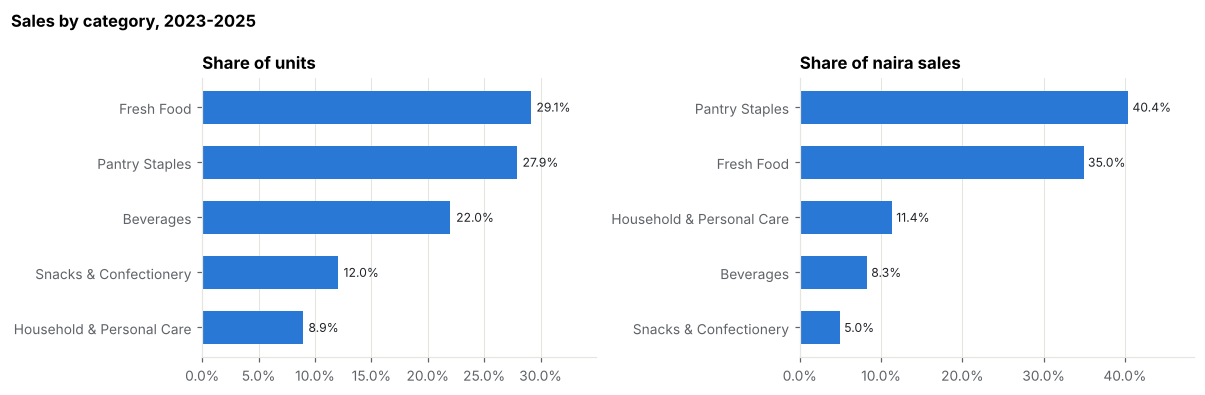

In [13]:
cat_tbl = td.groupby("category").agg(units=("units_sold", "sum"), value_ngn=("sales_value_ngn", "sum"))
cat_tbl["unit_share"] = cat_tbl.units / cat_tbl.units.sum()
cat_tbl["value_share"] = cat_tbl.value_ngn / cat_tbl.value_ngn.sum()
cat_tbl["avg_price_ngn"] = cat_tbl.value_ngn / cat_tbl.units
cat_tbl = cat_tbl.sort_values("units", ascending=False)
display(cat_tbl)

fam_tbl = td.groupby(["category", "family_name"]).agg(units=("units_sold", "sum"), value_ngn=("sales_value_ngn", "sum"))
fam_tbl["unit_share"] = fam_tbl.units / fam_tbl.units.sum()
fam_tbl["value_share"] = fam_tbl.value_ngn / fam_tbl.value_ngn.sum()
fam_tbl = fam_tbl.sort_values("units", ascending=False)
display(fam_tbl)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, ttl in ((axes[0], "unit_share", "Share of units"), (axes[1], "value_share", "Share of naira sales")):
    d = cat_tbl[col].sort_values()
    ax.barh(d.index, d.values, color=BLUE, height=0.6)
    for y, v in enumerate(d.values):
        ax.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=8, color=INK)
    ax.set_title(ttl); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, d.max() * 1.2)
fig.suptitle("Sales by category, 2023-2025", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "01_category_sales")
M["category"] = {c: dict(unit_share=round(r.unit_share * 100, 1), value_share=round(r.value_share * 100, 1)) for c, r in cat_tbl.iterrows()}
M["top_families_units"] = [f for _, f in fam_tbl.index[:3]]

**Categories by volume and value:**

| Category | Share of units | Share of naira sales |
|---|---|---|
| Fresh Food | 29.1% | 35.0% |
| Pantry Staples | 27.9% | 40.4% |
| Beverages | 22.0% | 8.3% |

- **Highest-volume families:** soft drinks (17% of units), noodles (14%) and snacks (12%).
- **Value leaders:** rice and grains is only 3.4% of units but the largest family by value (14.1%), followed by frozen meat and fish and cooking oils.

**Implication:** volume and value point to different priorities. High-volume, low-price families (drinks, noodles, snacks) drive store traffic and shelf replenishment workload. Rice, frozen and oils carry the most money tied up in each unit of stock.

### 6.3 Which stores have the highest sales?
Raw totals favour stores that are big or traded for longer. S08 opened in September 2024 and S03 closed for three weeks in 2024. I therefore rank stores on total sales, sales per trading day and sales per square metre.

,store_name,store_format,trading_days,units,value_ngn,units_per_day,value_m_per_day,value_per_sqm_day,value_2025_bn,rank_value_ngn,rank_units_per_day,rank_value_per_sqm_day
store_id,,,,,,,,,,,,
S02,Basketline Ikeja,hypermarket,1092,"6,727,390.000","13,466,231,192.000","6,160.614",12.332,"3,245.188",5.894,1,1,7
S01,Basketline Lekki,hypermarket,1093,"5,756,274.000","12,902,686,736.000","5,266.490",11.805,"2,810.675",5.801,2,2,8
S04,Basketline Wuse,supermarket,1093,"4,649,648.000","9,595,960,889.000","4,254.024",8.779,"3,376.719",4.069,3,3,6
S07,Basketline Nassarawa Kano,supermarket,1091,"4,294,651.000","8,381,182,590.000","3,936.435",7.682,"3,491.868",3.716,4,4,5
S05,Basketline GRA Port Harcourt,supermarket,1090,"3,855,127.000","8,096,744,315.000","3,536.814",7.428,"3,714.103",3.437,5,5,4
S03,Basketline Surulere,supermarket,1072,"3,747,762.000","7,252,980,342.000","3,496.047",6.766,"3,758.800",3.219,6,6,3
S06,Basketline Ring Road Ibadan,supermarket,1092,"3,749,196.000","7,023,644,352.000","3,433.330",6.432,"3,783.476",3.047,7,7,2
S08,Basketline Ajah Express,express,470,"677,557.000","1,460,913,882.000","1,441.611",3.108,"4,782.042",1.222,8,8,1


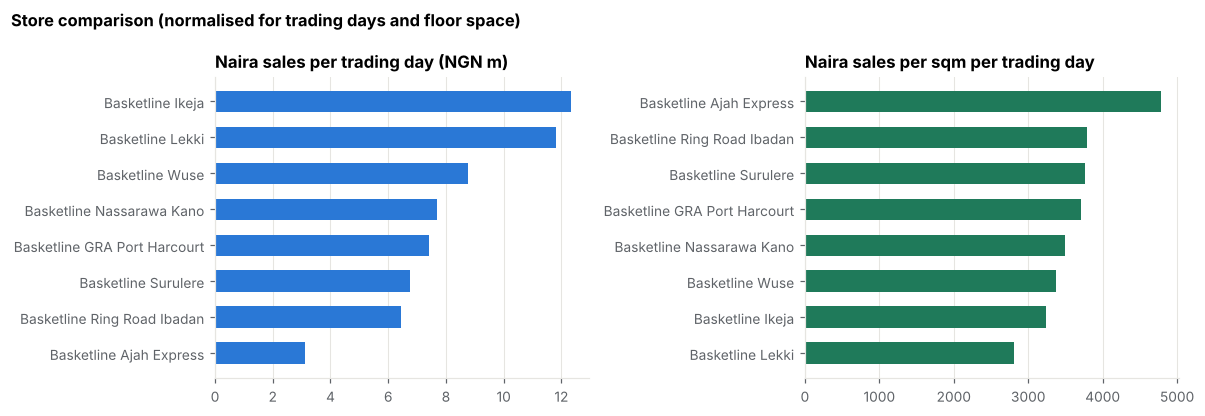

In [14]:
st_tbl = td.groupby("store_id").agg(units=("units_sold", "sum"), value_ngn=("sales_value_ngn", "sum"),
                                    trading_days=("sale_date", "nunique"))
st_tbl = st_tbl.join(stores.set_index("store_id")[["store_name", "store_format", "sales_area_sqm", "open_date"]])
st_tbl["units_per_day"] = st_tbl.units / st_tbl.trading_days
st_tbl["value_m_per_day"] = st_tbl.value_ngn / st_tbl.trading_days / 1e6
st_tbl["value_per_sqm_day"] = st_tbl.value_ngn / st_tbl.trading_days / st_tbl.sales_area_sqm
st_tbl["value_2025_bn"] = td[td.year == 2025].groupby("store_id").sales_value_ngn.sum() / 1e9
for c in ("units", "value_ngn", "units_per_day", "value_per_sqm_day"):
    st_tbl[f"rank_{c}"] = st_tbl[c].rank(ascending=False).astype(int)
st_tbl = st_tbl.sort_values("value_ngn", ascending=False)
display(st_tbl[["store_name", "store_format", "trading_days", "units", "value_ngn", "units_per_day", "value_m_per_day",
                "value_per_sqm_day", "value_2025_bn", "rank_value_ngn", "rank_units_per_day", "rank_value_per_sqm_day"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = st_tbl.sort_values("value_m_per_day")
axes[0].barh(d.store_name, d.value_m_per_day, color=BLUE, height=0.6)
axes[0].set_title("Naira sales per trading day (NGN m)")
d2 = st_tbl.sort_values("value_per_sqm_day")
axes[1].barh(d2.store_name, d2.value_per_sqm_day, color=GREEN, height=0.6)
axes[1].set_title("Naira sales per sqm per trading day")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Store comparison (normalised for trading days and floor space)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "02_store_ranking")
M["store_rank_value"] = st_tbl.store_name.tolist()
M["store_value_per_day_m"] = st_tbl.value_m_per_day.round(2).to_dict()
M["store_value_per_sqm_day"] = st_tbl.value_per_sqm_day.round(0).to_dict()

- **Highest sales:** S02 Ikeja (₦13.5bn over three years, ₦12.3m per trading day), followed by S01 Lekki (₦11.8m per day) and S04 Wuse (₦8.8m per day).
- **Floor-space productivity reverses the ranking:**
  - S08 Ajah Express is the most productive at ₦4,782 per sqm per day;
  - the two hypermarkets are the least productive (₦2,811-3,245).

Big stores win on total sales, while the small express format earns most per square metre. That is relevant if the chain is considering more express openings, though one store and 15 months of history is too little to generalise.

### 6.4 Units vs naira: is the business growing?
I use a like-for-like view of the stores open for the full three years, so that store openings do not distort the trend.

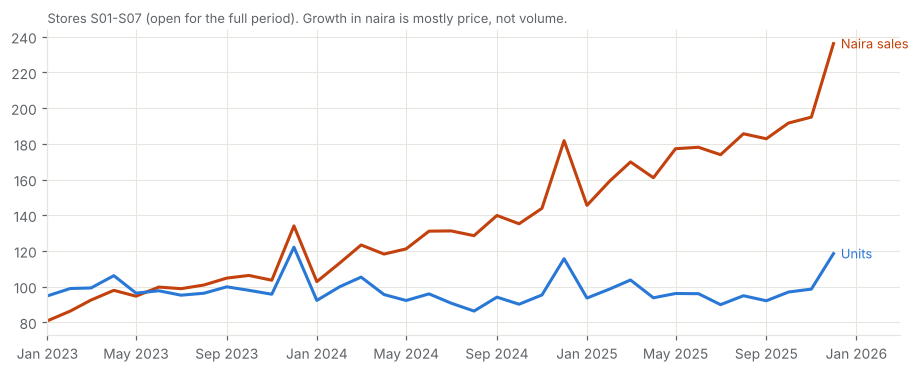

year,2023,2024,2025,growth_2025_vs_2023,price_growth_2025_vs_2023
family_name,,,,,
Frozen Meat & Fish,"395,210.000","364,713.000","351,493.000",-0.111,0.936
Soft Drinks & Water,"1,954,439.000","1,767,624.000","1,828,193.000",-0.065,0.981
Breakfast & Hot Beverages,"484,315.000","461,814.000","454,422.000",-0.062,0.803
Snacks & Confectionery,"1,358,400.000","1,284,842.000","1,276,735.000",-0.060,0.835
Rice & Grains,"388,216.000","374,383.000","368,733.000",-0.050,1.114
Household Cleaning,"523,872.000","527,845.000","504,276.000",-0.037,0.902
Dairy & Eggs,"706,187.000","690,552.000","680,757.000",-0.036,0.839
Personal Care,"465,368.000","452,355.000","461,586.000",-0.008,0.725
"Beer, Wine & Spirits","548,494.000","548,041.000","545,836.000",-0.005,0.541


In [15]:
mon = td.groupby(td.sale_date.dt.to_period("M")).agg(units=("units_sold", "sum"), value=("sales_value_ngn", "sum"))
lfl_stores = stores.loc[stores.open_date < "2023-01-01", "store_id"].tolist()          # like-for-like: open all 3 years
lfl = td[td.store_id.isin(lfl_stores)]
lfl_m = lfl.groupby(lfl.sale_date.dt.to_period("M")).agg(units=("units_sold", "sum"), value=("sales_value_ngn", "sum"),
                                                          days=("sale_date", "nunique"))
idx = (lfl_m[["units", "value"]].div(lfl_m.days, axis=0))
idx = idx / idx.iloc[:12].mean() * 100                                                 # 2023 average = 100

fig, ax = plt.subplots(figsize=(10, 3.6))
x = idx.index.to_timestamp()
ax.plot(x, idx.value, color=ORANGE, lw=2)
ax.plot(x, idx.units, color=BLUE, lw=2)
ax.text(x[-1], idx.value.iloc[-1], "  Naira sales", color=ORANGE, va="center", fontsize=8.5)
ax.text(x[-1], idx.units.iloc[-1], "  Units", color=BLUE, va="center", fontsize=8.5)
ax.set_title("Like-for-like stores: naira sales vs units per day (2023 average = 100)")
subtitle(ax, "Stores S01-S07 (open for the full period). Growth in naira is mostly price, not volume.")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=90))
save(fig, "03_units_vs_value")

lfl_y = lfl.groupby(["year", "family_name"]).units_sold.sum().unstack(0)
lfl_y["growth_2025_vs_2023"] = lfl_y[2025] / lfl_y[2023] - 1
lfl_price = lfl.groupby(["year", "family_name"]).apply(lambda g: g.sales_value_ngn.sum() / g.units_sold.sum()).unstack(0)
lfl_y["price_growth_2025_vs_2023"] = lfl_price[2025] / lfl_price[2023] - 1
display(lfl_y.sort_values("growth_2025_vs_2023"))
M["lfl_units_2025_vs_2023"] = round(float(lfl.groupby("year").units_sold.sum()[2025] / lfl.groupby("year").units_sold.sum()[2023] - 1) * 100, 1)
M["lfl_value_2025_vs_2023"] = round(float(lfl.groupby("year").sales_value_ngn.sum()[2025] / lfl.groupby("year").sales_value_ngn.sum()[2023] - 1) * 100, 1)
M["lfl_family_growth"] = lfl_y.growth_2025_vs_2023.round(3).sort_values().to_dict()
M["lfl_family_price_growth"] = lfl_y.price_growth_2025_vs_2023.round(3).to_dict()

**Like-for-like (stores open throughout):**

| Measure | 2025 vs 2023 |
|---|---|
| Units | -2.3% |
| Naira sales | +79.7% |

Families diverge in volume:
- **Fell:** frozen meat and fish -11%, soft drinks -6.5%, breakfast and hot beverages -6.2%, snacks -6%, rice -5%.
- **Grew slightly:** cooking oils, noodles, fresh produce and bread, each about +2-3%.

**Interpretation (hypothesis, not tested):** this pattern is consistent with shoppers protecting basic staples while cutting back on higher-priced protein and discretionary items under rising prices. Price elasticities cannot be confirmed without cost or competitor-price data.

## 7. Objective 2 - Seasonal patterns and demand fluctuations

### 7.1 Day-of-week and payday patterns
Each store-day is divided by that store's own 28-day centred average. This removes store size, trend and seasonality and isolates the weekday and within-month (payday) effects. Festive windows and public holidays are excluded so they do not distort the profile.

store_format,express,hypermarket,supermarket
Mon,1.029,0.832,0.873
Tue,0.991,0.806,0.842
Wed,1.043,0.846,0.883
Thu,1.019,0.922,0.949
Fri,1.135,1.091,1.082
Sat,1.006,1.422,1.319
Sun,0.773,1.052,1.019


Kruskal-Wallis (day-of-week differences), express     : H = 139, p = 1.9e-27
Kruskal-Wallis (day-of-week differences), hypermarket : H = 1,332, p = 1.4e-284
Kruskal-Wallis (day-of-week differences), supermarket : H = 2,421, p = 0.0e+00


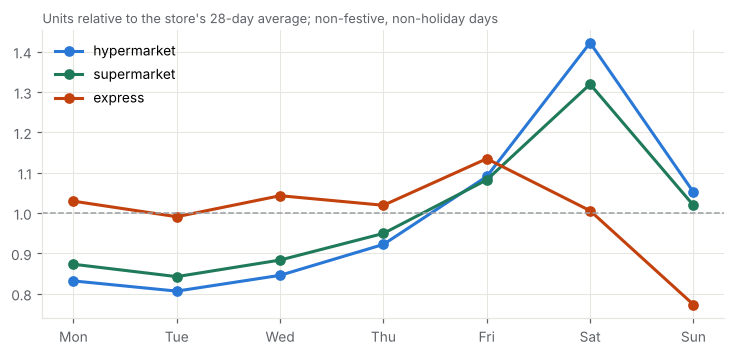

Payday window vs mid-month (all families): Mann-Whitney p < 1e-300


phase,mid-month,payday window,payday_effect
family_name,,,
Household Cleaning,0.932,1.101,0.181
Rice & Grains,0.939,1.088,0.158
Personal Care,0.942,1.074,0.140
Cooking Oils & Seasonings,0.941,1.070,0.137
Frozen Meat & Fish,0.953,1.057,0.109
Breakfast & Hot Beverages,0.960,1.059,0.103
Noodles & Pasta,0.969,1.048,0.081
Soft Drinks & Water,0.967,1.044,0.080
Dairy & Eggs,0.968,1.040,0.075


phase,mid-month,payday window,payday_effect
store_id,,,
S06,0.943,1.080,0.146
S03,0.949,1.074,0.131
S04,0.954,1.057,0.108
S02,0.956,1.055,0.103
S07,0.960,1.057,0.101
S05,0.968,1.048,0.083
S08,0.960,1.035,0.078
S01,0.977,1.025,0.049


In [16]:
# Store-day totals, normalised by each store's own 28-day centred average (removes store size, trend and season)
sd = td.groupby(["store_id", "sale_date", "store_format", "dow", "is_payday_window", "day_of_month", "festive",
                 "is_public_holiday"]).units_sold.sum().reset_index()
sd["level"] = sd.groupby("store_id").units_sold.transform(lambda s: s.rolling(28, center=True, min_periods=14).mean())
sd["index"] = sd.units_sold / sd.level
normal = sd[(sd.festive == 0) & (sd.is_public_holiday == 0)]
dow_idx = normal.groupby(["store_format", "dow"])["index"].mean().unstack(0)
dow_idx.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
display(dow_idx.round(3))
for fmt, g in normal.groupby("store_format"):
    h, p = stats.kruskal(*[x["index"].values for _, x in g.groupby("dow")])
    print(f"Kruskal-Wallis (day-of-week differences), {fmt:12s}: H = {h:,.0f}, p = {p:.1e}")

fig, ax = plt.subplots(figsize=(8, 3.4))
for col, c in zip(["hypermarket", "supermarket", "express"], [BLUE, GREEN, ORANGE]):
    ax.plot(dow_idx.index, dow_idx[col], marker="o", color=c, lw=2, label=col)
ax.axhline(1, color=GREY, lw=1, ls="--")
ax.set_title("Day-of-week demand index by store format")
subtitle(ax, "Units relative to the store's 28-day average; non-festive, non-holiday days")
ax.legend(loc="upper left")
save(fig, "04_day_of_week_profile")
M["dow_index"] = dow_idx.round(3).to_dict()

# Payday cycle: month-end/early-month window vs mid-month, by family
fd = td[(td.festive == 0) & (td.is_public_holiday == 0)].copy()
fd["level"] = fd.groupby(["store_id", "family_id"]).units_adj.transform(lambda s: s.rolling(28, center=True, min_periods=14).mean())
fd["dow_f"] = fd.groupby(["store_id", "family_id", "dow"]).units_adj.transform("mean") / fd.groupby(["store_id", "family_id"]).units_adj.transform("mean")
fd["index"] = fd.units_adj / fd.level / fd.dow_f
fd["phase"] = np.select([fd.is_payday_window == 1, fd.day_of_month.between(10, 20)], ["payday window", "mid-month"], "other")
pay = fd[fd.phase != "other"].groupby(["family_name", "phase"])["index"].mean().unstack()
pay["payday_effect"] = pay["payday window"] / pay["mid-month"] - 1
u, p = stats.mannwhitneyu(fd.loc[fd.phase == "payday window", "index"].dropna(), fd.loc[fd.phase == "mid-month", "index"].dropna())
print(f"Payday window vs mid-month (all families): Mann-Whitney p {'< 1e-300' if p == 0 else f'= {p:.1e}'}")
pay_store = fd[fd.phase != "other"].groupby(["store_id", "phase"])["index"].mean().unstack()
pay_store["payday_effect"] = pay_store["payday window"] / pay_store["mid-month"] - 1
display(pay.sort_values("payday_effect", ascending=False).round(3))
display(pay_store.sort_values("payday_effect", ascending=False).round(3))
M["payday_effect_family"] = pay.payday_effect.round(3).sort_values(ascending=False).to_dict()
M["payday_effect_store"] = pay_store.payday_effect.round(3).sort_values(ascending=False).to_dict()

**Weekday pattern depends on format.**

| Format | Peak | Low |
|---|---|---|
| Hypermarkets | Saturday, 42% above average | Tuesday, 19% below |
| Supermarkets | Saturday, +32% | - |
| Express | Friday | Sunday, 23% below average |

The express pattern suggests commuter and weekday convenience shopping. All differences are highly significant (Kruskal-Wallis, p < 1e-26).

**Payday cycle.** Demand in the salary window (last 6 days of the month and first 3) is clearly higher than mid-month (Mann-Whitney p < 1e-300).
- **By family:** the effect is largest for household cleaning (+18%), rice (+16%), personal care (+14%) and oils (+14%), and smallest for bread (+4%). Storable staples are bought when money arrives.
- **By store:** strongest in Ibadan (+15%) and Surulere (+13%), weakest in Lekki (+5%), the most affluent catchment.

**Implication:** staff rosters and ambient deliveries should be weighted to Friday-Saturday and to month-end, by store type.

### 7.2 Monthly seasonality by product family

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
family_name,,,,,,,,,,,,
"Beer, Wine & Spirits",0.880,1.000,1.010,0.930,0.940,0.910,0.980,0.900,0.950,0.980,1.040,1.480
Soft Drinks & Water,0.950,1.070,1.160,1.100,0.980,0.960,0.840,0.890,0.840,0.890,0.900,1.420
Frozen Meat & Fish,0.920,1.000,1.040,0.990,0.990,1.000,0.920,0.940,0.930,0.930,0.930,1.400
Fresh Produce,0.990,1.080,1.080,0.980,0.930,0.930,0.900,0.880,0.940,0.970,1.060,1.240
Rice & Grains,0.930,0.960,1.020,1.010,0.970,1.010,0.990,0.980,0.980,0.960,0.960,1.230
Cooking Oils & Seasonings,0.930,0.950,1.010,0.980,0.950,1.010,0.970,0.960,1.000,1.000,1.010,1.230
Snacks & Confectionery,0.960,1.010,1.000,0.970,0.950,0.960,0.930,0.940,1.170,0.950,0.970,1.200
Household Cleaning,1.000,1.030,0.980,0.970,0.970,1.020,0.940,0.960,1.000,0.970,1.020,1.140
Personal Care,0.930,1.010,0.990,0.980,1.020,1.020,0.980,0.980,1.010,0.980,0.990,1.140


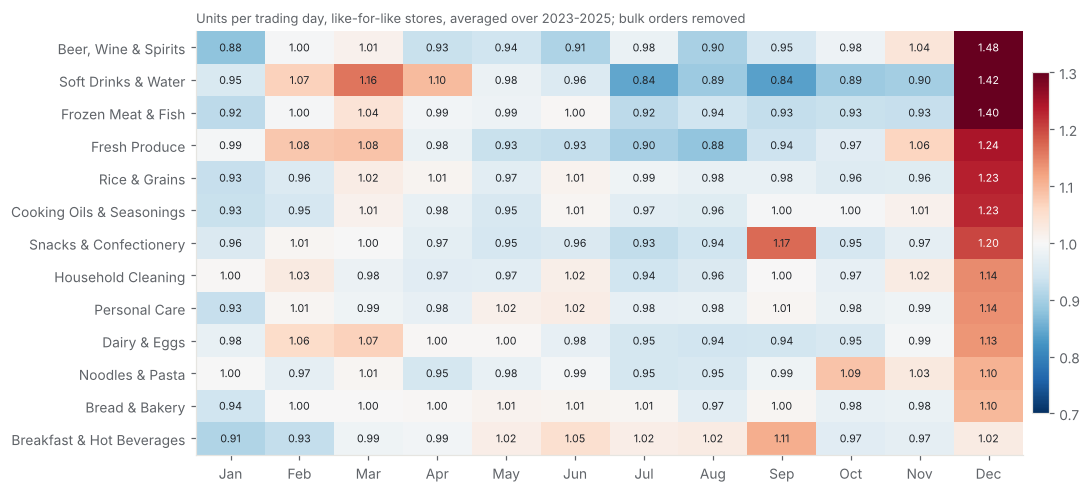

In [17]:
# Monthly seasonal index by family (like-for-like stores, units per day relative to the family's annual mean)
mm = lfl.copy()
mm["month"] = mm.sale_date.dt.month
mfam = mm.groupby(["family_name", "year", "month"]).agg(u=("units_adj", "sum"), d=("sale_date", "nunique"))
mfam["per_day"] = mfam.u / mfam.d
mfam["idx"] = mfam.per_day / mfam.groupby(["family_name", "year"]).per_day.transform("mean")
season_idx = mfam.groupby(["family_name", "month"]).idx.mean().unstack()
season_idx.columns = [pd.Timestamp(2024, m, 1).strftime("%b") for m in season_idx.columns]
season_idx = season_idx.loc[season_idx["Dec"].sort_values(ascending=False).index]
display(season_idx.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(season_idx.values, cmap="RdBu_r", vmin=0.7, vmax=1.3, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(season_idx.columns)
ax.set_yticks(range(len(season_idx))); ax.set_yticklabels(season_idx.index)
for i in range(season_idx.shape[0]):
    for j in range(12):
        v = season_idx.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v - 1) > 0.2 else INK)
ax.grid(False)
ax.set_title("Monthly seasonal index by product family (1.00 = family's annual average)")
subtitle(ax, "Units per trading day, like-for-like stores, averaged over 2023-2025; bulk orders removed")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
save(fig, "05_monthly_seasonality_heatmap")
M["dec_index"] = season_idx["Dec"].round(2).to_dict()
M["month_range"] = (season_idx.max(axis=1) - season_idx.min(axis=1)).round(2).sort_values(ascending=False).to_dict()

**December is the peak month for 12 of 13 families:** beer 1.48x, soft drinks 1.41x and frozen 1.40x their annual average.

Families with a different shape:
- **Soft drinks:** a second peak in the hot dry season (March 1.19x) and a trough in the rainy season (July and September 0.84x).
- **Breakfast and hot beverages:** the only family that peaks outside December (September 1.11x, back-to-school). Snacks also spike in September (1.17x).
- **Fresh produce:** dips in June-August (about 0.88-0.93x).
- **January:** below average for nearly every family.

### 7.3 Trend vs seasonality (STL) and which families are seasonal
STL decomposition splits weekly sales into trend, annual seasonality and remainder. **Seasonal strength** = 1 - Var(remainder) / Var(seasonal + remainder). A value near 1 means the annual pattern dominates the noise; near 0 means there is little repeatable seasonality.

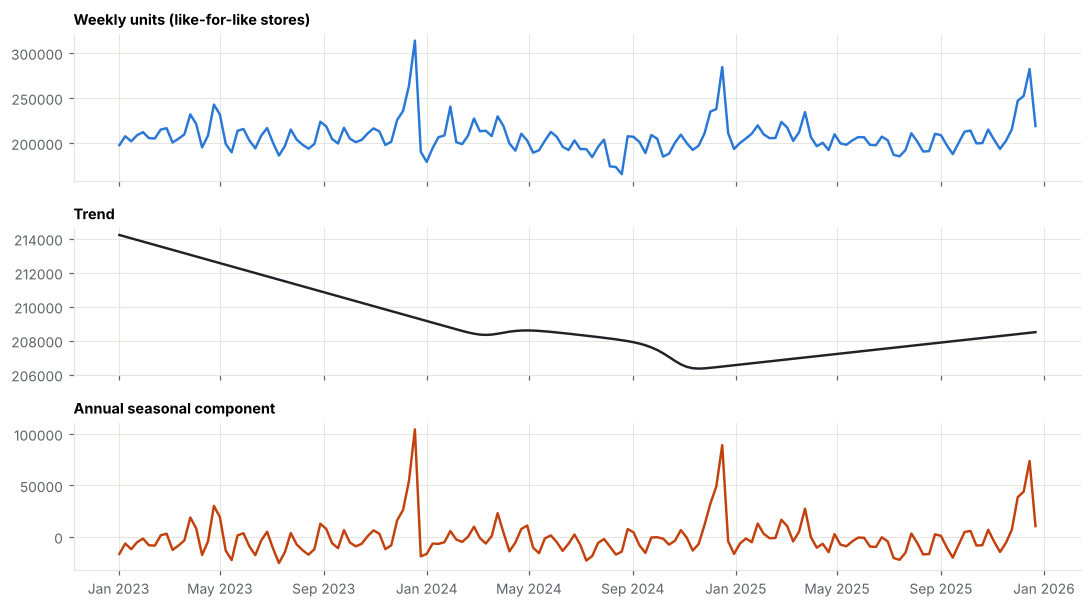

,seasonal_strength,december_index,peak_to_trough,class,peak_month
"Beer, Wine & Spirits",0.888,1.476,0.596,strongly seasonal,Dec
Soft Drinks & Water,0.904,1.418,0.580,strongly seasonal,Dec
Frozen Meat & Fish,0.923,1.403,0.481,strongly seasonal,Dec
Fresh Produce,0.798,1.244,0.363,strongly seasonal,Dec
Rice & Grains,0.900,1.233,0.302,moderately seasonal,Dec
Cooking Oils & Seasonings,0.805,1.227,0.294,moderately seasonal,Dec
Snacks & Confectionery,0.844,1.200,0.274,moderately seasonal,Dec
Personal Care,0.810,1.136,0.206,moderately seasonal,Dec
Household Cleaning,0.819,1.142,0.202,moderately seasonal,Dec
Breakfast & Hot Beverages,0.813,1.024,0.201,moderately seasonal,Sep


In [18]:
# STL decomposition of weekly chain units (like-for-like) and seasonal strength by family
wk = lfl[(lfl.week_start >= "2023-01-02") & (lfl.week_start <= "2025-12-22")]
chain_w = wk.groupby("week_start").units_adj.sum()
stl = STL(chain_w, period=52, robust=True).fit()
fig, axes = plt.subplots(3, 1, figsize=(10, 5.6), sharex=True)
for ax, s, ttl, c in zip(axes, [chain_w, stl.trend, stl.seasonal], ["Weekly units (like-for-like stores)", "Trend", "Annual seasonal component"], [BLUE, INK, ORANGE]):
    ax.plot(s.index, s.values, color=c, lw=1.6); ax.set_title(ttl, fontsize=9.5)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
save(fig, "06_stl_decomposition")


def seasonal_strength(s):
    r = STL(s, period=52, robust=True).fit()
    return max(0.0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid))


strength = {f: seasonal_strength(g.groupby("week_start").units_adj.sum()) for f, g in wk.groupby("family_name")}
seas = pd.DataFrame({"seasonal_strength": strength, "december_index": season_idx["Dec"],
                     "peak_to_trough": season_idx.max(axis=1) - season_idx.min(axis=1)}).sort_values("seasonal_strength", ascending=False)
# Weekly chain series are smooth, so STL strength is high for every family; the monthly amplitude separates them better
seas["class"] = pd.cut(seas.peak_to_trough, [0, 0.2, 0.35, 9], right=False, labels=["weakly seasonal", "moderately seasonal", "strongly seasonal"])
seas["peak_month"] = season_idx.idxmax(axis=1)
seas = seas.sort_values("peak_to_trough", ascending=False)
display(seas.round(3))
M["seasonal_class"] = seas["class"].astype(str).to_dict(); M["peak_month"] = seas.peak_month.to_dict()
M["seasonal_strength"] = seas.seasonal_strength.round(3).to_dict()
M["chain_weekly_seasonal_strength"] = round(seasonal_strength(chain_w), 3)

**Seasonal demand.** STL shows that the chain's weekly units are dominated by the annual cycle (seasonal strength 0.91). The trend dipped through 2024 and recovered modestly in 2025.

Weekly chain totals are smooth, so every family has high STL strength. The monthly peak-to-trough range separates them better:

| Group | Families | Peak-to-trough |
|---|---|---|
| Strongly seasonal | Beer/wine/spirits, soft drinks, frozen meat and fish, fresh produce | 0.36 to 0.60 |
| Moderately seasonal | Rice, oils, snacks, personal care, household, breakfast | 0.20 to 0.30 |
| Weakly seasonal | Dairy, bread, noodles | 0.15 to 0.19 |

**Implication:** the strongly seasonal families need season-aware forecasts and pre-built stock before peaks. For weakly seasonal families, recent level and weekday profile are enough.

### 7.4 Festive and regional events
Moving holidays shift each year, so calendar months alone miss them. Each event is lined up on its own date and compared with a pre-season baseline of the same days in the 3 weeks ending 4 weeks before.

,2023,2024,2025,mean
store_id,,,,
S01,1.001,0.893,1.001,0.965
S02,0.986,1.059,0.985,1.010
S03,1.160,1.052,0.939,1.050
S04,1.012,1.024,1.044,1.027
S05,1.041,0.874,0.947,0.954
S06,1.037,0.988,1.031,1.019
S07,1.155,1.125,1.100,1.127
S08,NaN,NaN,0.995,0.995


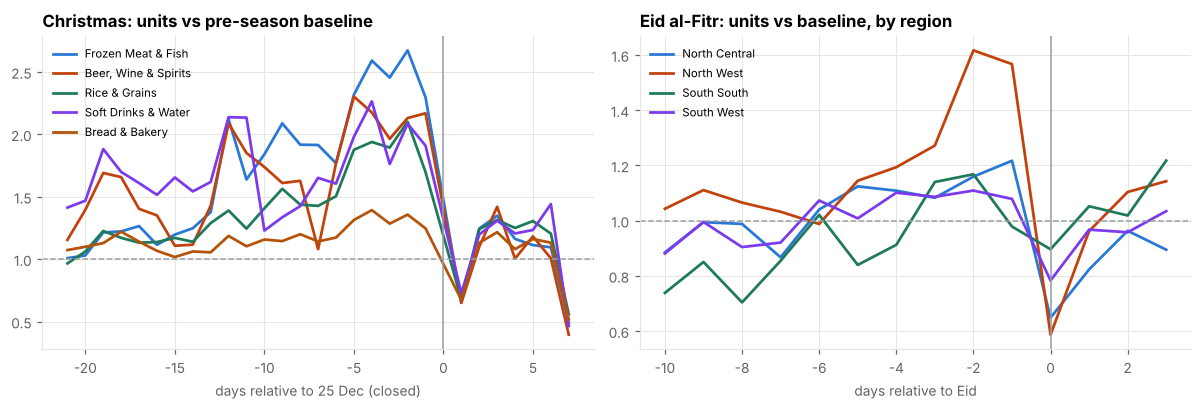

In [19]:
# Festive event profiles: units around each event relative to a pre-event baseline (same store-family, 3 weeks ending 4 weeks before)
def event_profile(anchor_dates, before=21, after=7, base_gap=28, base_len=21, by="family_name", subset=None):
    rows = []
    d0 = td if subset is None else td[subset]
    tot = d0.groupby(["sale_date", by]).units_adj.sum().unstack()
    for a in anchor_dates:
        base = tot.loc[a - pd.Timedelta(days=base_gap + base_len): a - pd.Timedelta(days=base_gap + 1)].mean()
        for k in range(-before, after + 1):
            day = a + pd.Timedelta(days=k)
            if day in tot.index:
                rows.append(pd.Series(tot.loc[day] / base, name=(a.year, k)))
    out = pd.DataFrame(rows)
    out.index = pd.MultiIndex.from_tuples(out.index, names=["year", "offset"])
    return out.groupby("offset").mean()

xmas_prof = event_profile([pd.Timestamp(f"{y}-12-25") for y in (2023, 2024, 2025)])
fitr = [d for d in hol.loc[hol.holiday_name == "Eid al-Fitr", "date"].groupby(hol.date.dt.year).min()]
eid_region = event_profile(fitr, before=10, after=3, by="region")
ram_rows = []
ram_periods = cal[cal.is_ramadan == 1].groupby(cal.date.dt.year).date.agg(["min", "max"])
for a, b in zip(ram_periods["min"], ram_periods["max"]):
    if a.year > 2025:
        continue
    pre = td[td.sale_date.between(a - pd.Timedelta(days=28), a - pd.Timedelta(days=1))].groupby("store_id").units_adj.sum() / 28
    dur = td[td.sale_date.between(a, b - pd.Timedelta(days=5))].groupby("store_id").units_adj.sum() / ((b - a).days - 4)
    ram_rows.append((dur / pre).rename(a.year))
ramadan = pd.concat(ram_rows, axis=1)
ramadan["mean"] = ramadan.mean(axis=1)
display(ramadan.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sel = ["Frozen Meat & Fish", "Beer, Wine & Spirits", "Rice & Grains", "Soft Drinks & Water", "Bread & Bakery"]
for f, c in zip(sel, CAT):
    axes[0].plot(xmas_prof.index, xmas_prof[f], color=c, lw=1.8, label=f)
axes[0].axhline(1, color=GREY, lw=1, ls="--"); axes[0].axvline(0, color=GREY, lw=1)
axes[0].set_title("Christmas: units vs pre-season baseline"); axes[0].set_xlabel("days relative to 25 Dec (closed)")
axes[0].legend(fontsize=7.5, loc="upper left")
for r, c in zip(eid_region.columns, CAT):
    axes[1].plot(eid_region.index, eid_region[r], color=c, lw=1.8, label=r)
axes[1].axhline(1, color=GREY, lw=1, ls="--"); axes[1].axvline(0, color=GREY, lw=1)
axes[1].set_title("Eid al-Fitr: units vs baseline, by region"); axes[1].set_xlabel("days relative to Eid")
axes[1].legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
save(fig, "07_festive_profiles")
M["xmas_peak_index"] = xmas_prof.loc[-7:-1].max().round(2).sort_values(ascending=False).to_dict()
M["eid_peak_by_region"] = eid_region.loc[-5:-1].max().round(2).to_dict()
M["ramadan_ratio_by_store"] = ramadan["mean"].round(3).to_dict()

**Festive and regional events matter more than months suggest.**
- **Christmas:** in the final week before Christmas, frozen meat and fish sells **2.7x** its pre-season level, beer 2.3x, soft drinks 2.3x and rice 2.1x. Bread (1.4x) and noodles (1.3x) barely move.
- **Eid al-Fitr is regional.** Sales in the days before Eid reach **1.6x** baseline in the North West (Kano), compared with 1.1-1.2x elsewhere. This is measured after removing bulk orders: an unflagged 18,000-unit B2B order before Eid 2025 would have inflated it to 2.7x.
- **Ramadan:** lifts Kano by 13% over the month. Some southern stores dip slightly (Port Harcourt -5%, Lekki -3%).

**Implication:** a single chain-wide seasonal plan would under-stock Kano before Eid and over-stock southern stores during Ramadan.

**Caveat:** in some years the Eid window falls close to Easter, so the southern profile partly reflects Easter shopping. Each regional estimate rests on three events.

### 7.5 Which products have volatile or stable demand?
Raw variability mixes predictable patterns (weekday, season, promotions) with genuine noise. Volatility is therefore measured on ordinary days only: no promotion or post-promotion window, stock-out, bulk order, festive window or holiday. It is the coefficient of variation of daily units relative to each series' expected level (28-day centred mean x weekday profile).

Bands:
- **stable:** CV < 0.25;
- **moderate:** 0.25-0.40;
- **volatile:** > 0.40.

,series
class,
stable,58
moderate,41
volatile,4


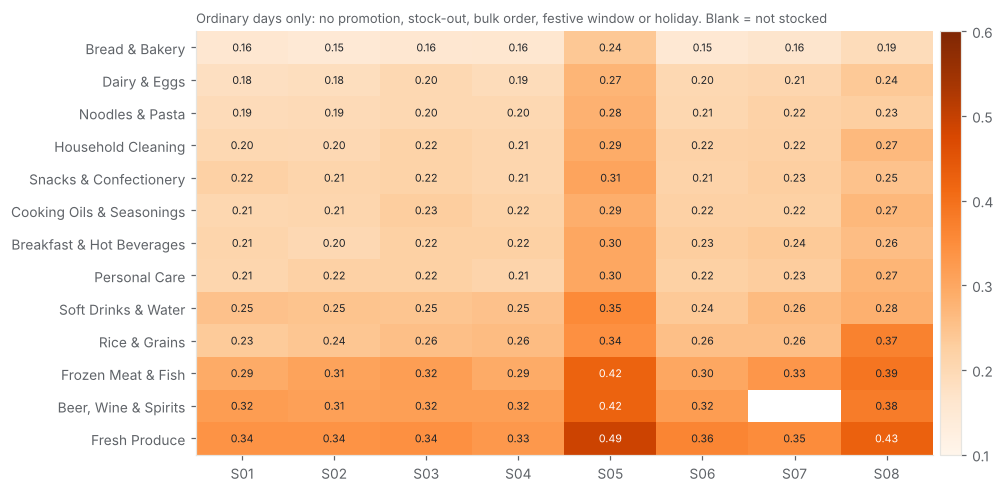

family_name,Bread & Bakery,Dairy & Eggs,Noodles & Pasta,Household Cleaning,Snacks & Confectionery,Cooking Oils & Seasonings,Breakfast & Hot Beverages,Personal Care,Soft Drinks & Water,Rice & Grains,Frozen Meat & Fish,"Beer, Wine & Spirits",Fresh Produce
mean baseline CV (family),0.170,0.210,0.215,0.228,0.231,0.232,0.235,0.236,0.267,0.277,0.332,0.341,0.372


store_id,S01,S02,S04,S03,S06,S07,S08,S05
mean baseline CV (store),0.232,0.232,0.236,0.242,0.242,0.243,0.294,0.332


In [20]:
# Volatility: noise around each series' expected pattern (local level x weekday profile) on ordinary days
nd = td[(td.on_promotion == 0) & (td.post_promo == 0) & (td.stockout_flag == 0) & (td.bulk_flag == 0) & (td.festive == 0)
        & (td.is_public_holiday == 0)].copy()
grp = nd.groupby(["store_id", "family_id"])
nd["level"] = grp.units_adj.transform(lambda s: s.rolling(28, center=True, min_periods=14).mean())
nd["dowf"] = nd.groupby(["store_id", "family_id", "dow"]).units_adj.transform("mean") / grp.units_adj.transform("mean")
nd["rel"] = nd.units_adj / (nd.level * nd.dowf)
vol = nd.groupby(["store_id", "family_name"]).rel.std().rename("baseline_cv").reset_index()
vol = vol.merge(td.groupby(["store_id", "family_name"]).units_sold.agg(lambda s: s.std() / s.mean()).rename("total_cv").reset_index())
vol["class"] = pd.cut(vol.baseline_cv, [0, 0.25, 0.40, 9], labels=["stable", "moderate", "volatile"])
vmat = vol.pivot(index="family_name", columns="store_id", values="baseline_cv")
vmat = vmat.loc[vmat.mean(axis=1).sort_values().index]
display(vol["class"].value_counts().to_frame("series"))

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(vmat.values, cmap="Oranges", vmin=0.1, vmax=0.6, aspect="auto")
ax.set_xticks(range(vmat.shape[1])); ax.set_xticklabels(vmat.columns)
ax.set_yticks(range(vmat.shape[0])); ax.set_yticklabels(vmat.index)
for i in range(vmat.shape[0]):
    for j in range(vmat.shape[1]):
        v = vmat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.42 else INK)
ax.grid(False)
ax.set_title("Baseline demand volatility (CV of daily units around expected pattern)")
subtitle(ax, "Ordinary days only: no promotion, stock-out, bulk order, festive window or holiday. Blank = not stocked")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
save(fig, "08_volatility_heatmap")
fam_vol = vol.groupby("family_name").baseline_cv.mean().sort_values()
store_vol = vol.groupby("store_id").baseline_cv.mean().sort_values()
display(pd.concat([fam_vol.rename("mean baseline CV (family)")], axis=1).round(3).T)
display(store_vol.round(3).to_frame("mean baseline CV (store)").T)
M["family_cv"] = fam_vol.round(3).to_dict(); M["store_cv"] = store_vol.round(3).to_dict()
M["volatility_classes"] = vol["class"].value_counts().to_dict()
vol.to_csv(RESULTS / "volatility_by_series.csv", index=False)

**Stable vs volatile demand** (series = one store-family combination):
- **Stable:** 58 of 103 series.
- **Moderate:** 41 series.
- **Volatile:** 4 series, three of them in Port Harcourt (S05): fresh produce (CV 0.49), frozen, and beer, wine and spirits, plus fresh produce in the new Ajah Express store.

**By family:**
- **Most stable:** bread (CV about 0.17), dairy (0.21) and noodles (0.22).
- **Least stable:** fresh produce (0.37), beer, wine and spirits (0.34) and frozen (0.33).

**By store:** S05 Port Harcourt (0.33) and S08 Ajah Express (0.29) are noisier than every other store (0.23-0.24). The same family behaves differently by store, so volatility belongs to the store-family series, not just the product. This is why one safety-stock rule for all series is a poor fit.

## 8. Objective 3 - Promotions and sales performance

### 8.1 First look: promotional vs non-promotional days

In [21]:
naive = td.groupby(["family_name", "on_promotion"]).units_sold.mean().unstack()
naive["naive_ratio"] = naive[1] / naive[0]
display(naive.sort_values("naive_ratio", ascending=False).round(2))
print("Promotion rows by month share vs all rows by month share (shows promotions are not spread evenly through the year):")
display(pd.DataFrame({"promo_rows": td[td.on_promotion == 1].sale_date.dt.month.value_counts(normalize=True).sort_index(),
                      "all_rows": td.sale_date.dt.month.value_counts(normalize=True).sort_index()}).T.round(3))

on_promotion,0.000,1.000,naive_ratio
family_name,,,
Household Cleaning,189.540,267.950,1.410
"Beer, Wine & Spirits",229.100,318.360,1.390
Snacks & Confectionery,482.600,656.010,1.360
Soft Drinks & Water,677.310,876.000,1.290
Noodles & Pasta,571.900,711.060,1.240
Cooking Oils & Seasonings,246.070,291.410,1.180
Personal Care,171.520,199.140,1.160
Breakfast & Hot Beverages,174.870,202.800,1.160
Rice & Grains,139.730,159.200,1.140


Promotion rows by month share vs all rows by month share (shows promotions are not spread evenly through the year):


sale_date,1,2,3,4,5,6,7,8,9,10,11,12
promo_rows,0.112,0.073,0.109,0.071,0.066,0.058,0.052,0.064,0.103,0.103,0.114,0.074
all_rows,0.084,0.077,0.084,0.082,0.084,0.082,0.084,0.082,0.083,0.088,0.085,0.085


On promotion days, average units are 9% (fresh produce) to 41% (household cleaning) higher than on other days. These raw ratios are **not reliable effect sizes**, because promotions are clustered:
- **More often in:** January, March and September to November.
- **Less often in:** June-July and December.

Any seasonal difference between those periods is mixed into the comparison. Section 8.2 corrects for this.

### 8.2 Separating the promotion effect from everything else
Promotions are scheduled around seasons, so the naive comparison is confounded. I fit one log-linear regression per product family on non-stock-out, non-bulk days:

`log(1 + units) = store level + store trend + format x weekday + month + Christmas/January/Easter windows + holidays + payday + back-to-school + store x (Ramadan, Eid) + store events + promotion + post-promotion`

- **Promotion coefficient:** exp(b) - 1 is the average uplift.
- **Post-promotion coefficient:** measures any dip in the 14 days after a promotion ends (pull-forward of storable goods).
- **Standard errors:** clustered by store-week to allow for correlated errors within a week.

The model is used for attribution, not causal proof: it controls for the measured calendar drivers, but promotions were not randomised.

,term,effect,ci_low,ci_high,p_value,r2,n
family_name,,,,,,,
Household Cleaning,on_promotion,0.399,0.341,0.459,0.000,0.773,8030
Noodles & Pasta,on_promotion,0.328,0.288,0.369,0.000,0.708,8000
"Beer, Wine & Spirits",on_promotion,0.297,0.250,0.344,0.000,0.672,6904
Soft Drinks & Water,on_promotion,0.270,0.228,0.314,0.000,0.650,7946
Snacks & Confectionery,on_promotion,0.270,0.234,0.307,0.000,0.674,7968
Cooking Oils & Seasonings,on_promotion,0.237,0.200,0.274,0.000,0.793,7973
Rice & Grains,on_promotion,0.194,0.156,0.233,0.000,0.773,7960
Breakfast & Hot Beverages,on_promotion,0.188,0.151,0.226,0.000,0.729,7991
Personal Care,on_promotion,0.137,0.108,0.167,0.000,0.748,8004


,term,effect,ci_low,ci_high,p_value,r2,n
family_name,,,,,,,
Household Cleaning,post_promo,-0.072,-0.094,-0.049,0.000,0.773,8030
Noodles & Pasta,post_promo,-0.062,-0.083,-0.040,0.000,0.708,8000
"Beer, Wine & Spirits",post_promo,-0.049,-0.077,-0.019,0.001,0.672,6904
Soft Drinks & Water,post_promo,-0.048,-0.073,-0.023,0.000,0.650,7946
Snacks & Confectionery,post_promo,-0.042,-0.065,-0.018,0.001,0.674,7968
Cooking Oils & Seasonings,post_promo,-0.029,-0.053,-0.006,0.015,0.793,7973
Personal Care,post_promo,-0.028,-0.050,-0.006,0.014,0.748,8004
Rice & Grains,post_promo,-0.027,-0.053,0.001,0.055,0.773,7960
Breakfast & Hot Beverages,post_promo,-0.019,-0.042,0.005,0.129,0.729,7991


Model fit (R-squared) range across families: 0.51-0.79 | all designs full rank


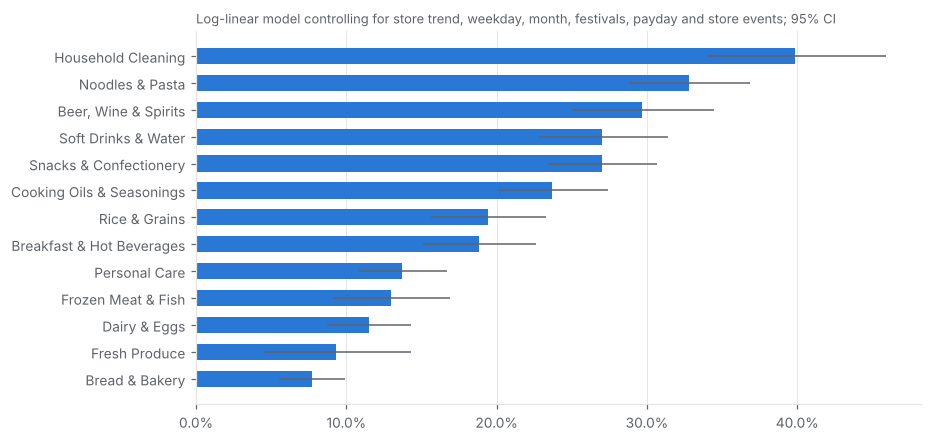

In [22]:
# Per-family log-linear baseline model: separates promotion effects from store level/trend, weekday, month,
# festive windows, regional festivals, payday and store events. Stock-out and bulk days are excluded (censored / atypical).
s08_open = pd.Timestamp("2024-09-16")


def design(frame):
    """Add model columns. Coding is full rank: December windows are relative to 1-10 Dec (absorbed by the
    month effect), weekday x format effects are relative to supermarkets, and S08 ramp weeks are relative
    to its steady state (absorbed by the S08 store effect)."""
    d = frame.copy()
    d["t"] = (d.sale_date - pd.Timestamp("2023-01-01")).dt.days / 365.25
    d["month"] = d.sale_date.dt.month
    d["s04_post"] = ((d.store_id == "S04") & (d.sale_date >= "2024-06-03")).astype(int)
    d["s03_post"] = ((d.store_id == "S03") & (d.sale_date >= "2024-08-26")).astype(int)
    wk = (d.sale_date - s08_open).dt.days // 7
    d["s08_week"] = np.where((d.store_id == "S08") & (wk < 12), wk, -1).astype(str)
    for k in range(1, 7):
        d[f"dow{k}_hyper"] = ((d.dow == k) & (d.store_format == "hypermarket")).astype(int)
        d[f"dow{k}_express"] = ((d.dow == k) & (d.store_format == "express")).astype(int)
    return d


md_ = design(td[(td.stockout_flag == 0) & (td.bulk_flag == 0)])
md_["y"] = np.log1p(md_.units_adj)
DOWX = " + ".join(f"dow{k}_hyper + dow{k}_express" for k in range(1, 7))
FORMULA = ("y ~ C(store_id) + C(store_id):t + C(dow) + " + DOWX + " + C(month) + win_xmas_mid + win_xmas_late"
           " + win_dec_post + win_jan_slump + win_easter + is_public_holiday + is_payday_window + is_back_to_school"
           " + C(store_id):is_ramadan + C(store_id):win_eid + s04_post + s03_post + C(s08_week)"
           " + on_promotion + post_promo")
fits, coefs = {}, []
for f, g in md_.groupby("family_name"):
    form = FORMULA.replace(" + s04_post", "" if g.s04_post.sum() else "").replace(" + s03_post", "" if g.s03_post.sum() else "")
    res = smf.ols(form, data=g).fit(cov_type="cluster", cov_kwds={"groups": (g.store_id + g.week_start.dt.strftime("%Y%W")).values})
    assert res.df_model + 1 == res.model.exog.shape[1], f"rank-deficient design for {f}"
    fits[f] = res
    for term in ("on_promotion", "post_promo"):
        b, (lo, hi) = res.params[term], res.conf_int().loc[term]
        coefs.append(dict(family_name=f, term=term, effect=np.exp(b) - 1, ci_low=np.exp(lo) - 1, ci_high=np.exp(hi) - 1,
                          p_value=res.pvalues[term], r2=res.rsquared, n=int(res.nobs)))
coef = pd.DataFrame(coefs)
promo_eff = coef[coef.term == "on_promotion"].set_index("family_name").sort_values("effect", ascending=False)
post_eff = coef[coef.term == "post_promo"].set_index("family_name").sort_values("effect")
display(promo_eff.round(3))
display(post_eff.round(3))
print("Model fit (R-squared) range across families:", f"{coef.r2.min():.2f}-{coef.r2.max():.2f}", "| all designs full rank")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
d = promo_eff.sort_values("effect")
ax.barh(d.index, d.effect, color=BLUE, height=0.6, xerr=[d.effect - d.ci_low, d.ci_high - d.effect], error_kw=dict(ecolor=MUTED, lw=1))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.grid(axis="y", visible=False)
ax.set_title("Estimated promotion uplift by product family")
subtitle(ax, "Log-linear model controlling for store trend, weekday, month, festivals, payday and store events; 95% CI")
save(fig, "09_promo_uplift_by_family")
M["promo_uplift_family"] = promo_eff.effect.round(3).to_dict()
M["post_promo_effect_family"] = post_eff[["effect", "p_value"]].round(3).to_dict("index")
M["promo_model_r2_range"] = [round(coef.r2.min(), 2), round(coef.r2.max(), 2)]

**Promotion uplift after controlling for seasonality, trend, festivals and store events** (all significant, p < 0.001):
- **Largest:** household cleaning **+40%** (95% CI 34-46%), noodles +33%, beer +30%, soft drinks +27%, snacks +27%.
- **Smallest:** bread +8% and fresh produce +9%, even though promotions on them still cost margin.

**Post-promotion dip.** Several storable families sell less in the 14 days after a promotion, which shows shoppers stocking up:
- household -7%, noodles -6%, beer -5%, soft drinks -5% and snacks -4% (all p < 0.01), plus smaller dips for oils and personal care (-3%, p < 0.05);
- for household cleaning, roughly a quarter of the extra volume from a typical 10-day promotion is given back afterwards;
- no measurable dip for bread, dairy, fresh produce or frozen.

**Model fit:** R-squared is 0.51-0.79. The estimates are associations controlled for measured drivers, not randomised causal effects.

### 8.3 Event-level uplift: every promotion at every store
For each promotion x store, I compare actual units with the model's prediction for the same days with the promotion switched off. The prediction uses a smearing correction for the log transform. I also record two further measures:
- **Raw before/after ratio:** units per day versus the 4 weeks before.
- **Achieved price change:** the actual change in average selling price.

In [23]:
# Event-level results: actual units vs the model's no-promotion baseline for every promotion x store
pr_rows = design(td[td.on_promotion == 1])
base = []
for f, g in pr_rows.groupby("family_name"):
    res = fits[f]
    smear = np.mean(np.exp(res.resid))                                    # Duan smearing for log back-transform
    g0 = g.assign(on_promotion=0, post_promo=0)
    base.append(pd.Series(np.exp(res.predict(g0)) * smear - 1, index=g.index))
pr_rows["baseline"] = pd.concat(base)

# pre-period (28 days before the promotion, non-promotion trading days) for a raw before/after view and price check
pre_stats = []
for (pid, sid), g in pr_rows.groupby(["promotion_id", "store_id"]):
    start = g.sale_date.min()
    pre = td[(td.store_id == sid) & (td.family_id == g.family_id.iloc[0]) & td.sale_date.between(start - pd.Timedelta(days=28), start - pd.Timedelta(days=1))
             & (td.on_promotion == 0)]
    pre_stats.append(dict(promotion_id=pid, store_id=sid, pre_units_per_day=pre.units_adj.mean(),
                          pre_price=(pre.sales_value_ngn.sum() / pre.units_sold.sum()) if len(pre) else np.nan))
pre_stats = pd.DataFrame(pre_stats)
ev = pr_rows.groupby(["promotion_id", "store_id"]).agg(family_name=("family_name", "first"), promo_type=("promo_type", "first"),
        discount_pct=("discount_pct", "first"), start=("sale_date", "min"), days=("sale_date", "count"),
        units=("units_sold", "sum"), baseline=("baseline", "sum"), stockout_days=("stockout_flag", "sum"),
        promo_value=("sales_value_ngn", "sum")).reset_index().merge(pre_stats)
ev["promo_price"] = ev.promo_value / ev.units
ev["uplift"] = ev.units / ev.baseline                      # 1.00 = no change vs modelled baseline
ev["vs_pre_period"] = (ev.units / ev.days) / ev.pre_units_per_day
ev["price_change"] = ev.promo_price / ev.pre_price - 1
ev["stockout_share"] = ev.stockout_days / ev.days
ev = ev.merge(promos[["promotion_id", "promotion_name"]])
ev.to_csv(RESULTS / "promotion_event_results.csv", index=False)
print(f"{len(ev)} promotion x store events; median uplift {ev.uplift.median():.2f}; "
      f"{(ev.uplift < 1).mean():.1%} below their modelled baseline; {(ev.vs_pre_period < 1).mean():.1%} below the pre-period average")

by_type = ev.groupby("promo_type").uplift.describe()[["count", "25%", "50%", "75%"]]
display(by_type.round(3))
pdisc = ev[ev.promo_type == "price_discount"]
rho, p = stats.spearmanr(pdisc.discount_pct, pdisc.uplift)
print(f"Price discounts: Spearman correlation of headline discount with uplift = {rho:.2f} (p = {p:.1e})")
M["event_count"] = len(ev); M["event_median_uplift"] = round(ev.uplift.median(), 3)
M["uplift_by_type_median"] = by_type["50%"].round(3).to_dict(); M["discount_uplift_spearman"] = round(rho, 2)

768 promotion x store events; median uplift 1.17; 9.9% below their modelled baseline; 14.1% below the pre-period average


,count,25%,50%,75%
promo_type,,,,
display_feature,125.000,1.046,1.136,1.241
multibuy,114.000,1.223,1.358,1.609
price_discount,529.000,1.068,1.158,1.268


Price discounts: Spearman correlation of headline discount with uplift = 0.14 (p = 9.9e-04)


**Event results (768 promotion-store events):**
- **Typical result:** median uplift 1.17 (17% above the no-promotion baseline).
- **By mechanic:**
  - multibuy: median **1.36**, clearly the strongest;
  - price discounts: 1.16;
  - featured-aisle displays (no price cut): 1.14, almost the same as price discounts at no margin cost.
- **Discount depth:** only weakly related to uplift (Spearman 0.14). Deeper discounts buy little extra volume.
- **Achieved price change:** the median price-based promotion lowered the family's average price by 8.8% against a 20% headline. Only part of each family is on offer, which matters when promotion costs are estimated.

### 8.4 Do promotions produce similar results across outlets?

,events,median_uplift,q25,q75,store_name,store_format
store_id,,,,,,
S06,92,1.279,1.166,1.431,Basketline Ring Road Ibadan,supermarket
S02,116,1.211,1.091,1.381,Basketline Ikeja,hypermarket
S03,112,1.211,1.109,1.332,Basketline Surulere,supermarket
S05,94,1.209,1.075,1.354,Basketline GRA Port Harcourt,supermarket
S04,99,1.157,1.065,1.260,Basketline Wuse,supermarket
S07,87,1.123,1.069,1.237,Basketline Nassarawa Kano,supermarket
S01,115,1.113,1.025,1.212,Basketline Lekki,hypermarket
S08,53,1.113,1.047,1.196,Basketline Ajah Express,express


Kruskal-Wallis test of uplift differences between stores: H = 73.6, p = 2.8e-13
Within the 86 promotions run in 6+ stores, the median gap between the best and worst store uplift is 0.40


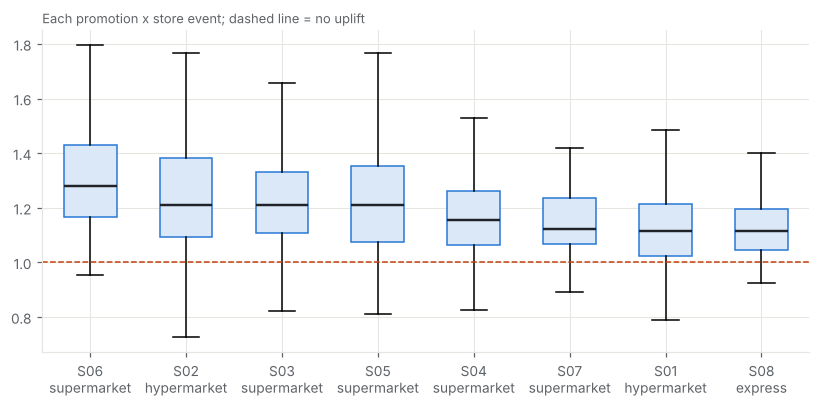

In [24]:
st_up = ev.groupby("store_id").uplift.agg(["count", "median", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])
st_up.columns = ["events", "median_uplift", "q25", "q75"]
st_up = st_up.join(stores.set_index("store_id")[["store_name", "store_format"]]).sort_values("median_uplift", ascending=False)
display(st_up.round(3))
h, p = stats.kruskal(*[g.uplift.values for _, g in ev.groupby("store_id")])
print(f"Kruskal-Wallis test of uplift differences between stores: H = {h:.1f}, p = {p:.1e}")
# same promotion, different stores: spread of uplift within chain-wide promotions
multi = ev.groupby("promotion_id").filter(lambda g: len(g) >= 6)
spread = multi.groupby("promotion_id").uplift.agg(lambda s: s.max() - s.min())
print(f"Within the {multi.promotion_id.nunique()} promotions run in 6+ stores, the median gap between the best and worst store uplift is {spread.median():.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
order = st_up.index.tolist()
data = [ev.loc[ev.store_id == s, "uplift"].clip(upper=3) for s in order]
bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.55, showfliers=False)
for b in bp["boxes"]:
    b.set(facecolor="#dbe8f8", edgecolor=BLUE)
for m in bp["medians"]:
    m.set(color=INK, lw=1.6)
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([f"{s}\n{stores.set_index('store_id').store_format[s]}" for s in order])
ax.axhline(1, color=ORANGE, ls="--", lw=1)
ax.set_title("Promotion uplift by store (actual / modelled baseline)")
subtitle(ax, "Each promotion x store event; dashed line = no uplift")
save(fig, "10_promo_uplift_by_store")
M["store_median_uplift"] = st_up.median_uplift.round(3).to_dict(); M["store_uplift_kruskal_p"] = float(f"{p:.2e}")
M["within_promo_uplift_spread_median"] = round(float(spread.median()), 2)

**No - the same promotion performs differently across outlets.**
- **Strongest median uplift:** Ibadan (1.28), Ikeja and Surulere (1.21).
- **Weakest:** Lekki (1.11) and Ajah Express (1.11).
- **Statistical test:** the differences are highly significant (Kruskal-Wallis p = 3e-13).
- **Within a single chain-wide promotion:** the best and worst stores typically differ by 0.40 in uplift.

This matches the payday pattern: price-sensitive catchments respond to promotions, while the affluent Lekki store and the small express store respond far less. **Implication:** chain-wide promotions waste margin in low-response stores. Promotion allocation should be store-specific.

### 8.5 Are there occasions when promotions coincide with lower sales?
An event is reviewed if its sales per day fell below the 4 weeks before, or if it came in below its modelled baseline. Each case is classified with simple, auditable rules:
1. **Stock-outs during the promotion:** at least 30% of promotion days had a stock-out.
2. **Discount not reflected in the shelf price:** a price or multibuy promotion where the average price did not fall.
3. **Seasonal timing:** above the modelled baseline but below the pre-period, so the season was falling.
4. **Weak or no response:** none of the above.

,events
diagnosis,
weak or no response,70
seasonal timing (baseline falling),33
stock-outs during promotion,8
discount not reflected in shelf price,2


,promotion_id,promotion_name,store_id,start,promo_type,discount_pct,vs_pre_period,uplift,price_change,stockout_share,diagnosis
290,PR24-011,Ramadan Staples Saver - Rice 2024,S04,2024-03-11,price_discount,0.150,0.654,0.640,-0.073,0.857,stock-outs during promotion
469,PR25-002,Price Drop - Cooking Oils & Seasonings,S05,2025-01-09,price_discount,0.100,0.659,1.021,-0.074,0.000,weak or no response
384,PR24-031,Price Drop - Rice & Grains,S01,2024-09-19,price_discount,0.200,0.708,0.788,-0.068,0.000,weak or no response
246,PR24-002,Price Drop - Rice & Grains,S05,2024-01-11,price_discount,0.150,0.709,1.039,-0.103,0.071,weak or no response
617,PR25-025,Price Drop - Frozen Meat & Fish,S07,2025-06-26,price_discount,0.150,0.791,0.792,-0.089,0.500,stock-outs during promotion
531,PR25-012,Price Drop - Fresh Produce,S07,2025-03-20,price_discount,0.250,0.801,0.782,-0.094,0.429,stock-outs during promotion
177,PR23-033,Featured Aisle - Rice & Grains,S01,2023-10-26,display_feature,0.000,0.809,0.795,0.040,0.000,weak or no response
418,PR24-035,"Featured Aisle - Beer, Wine & Spirits",S03,2024-10-17,display_feature,0.000,0.811,0.844,0.006,0.000,weak or no response
752,PR25-044,Price Drop - Breakfast & Hot Beverages,S08,2025-11-13,price_discount,0.200,0.819,0.946,-0.125,0.000,weak or no response
291,PR24-011,Ramadan Staples Saver - Rice 2024,S07,2024-03-11,price_discount,0.150,0.819,0.744,-0.069,0.714,stock-outs during promotion


,promotion_id,promotion_name,store_id,start,promo_type,discount_pct,vs_pre_period,uplift,price_change,stockout_share,diagnosis
341,PR24-022,Price Drop - Bread & Bakery,S07,2024-07-04,price_discount,0.300,0.982,1.014,0.002,0.000,discount not reflected in shelf price
741,PR25-043,Price Drop - Personal Care,S05,2025-10-30,price_discount,0.250,0.864,0.988,-0.007,0.000,discount not reflected in shelf price


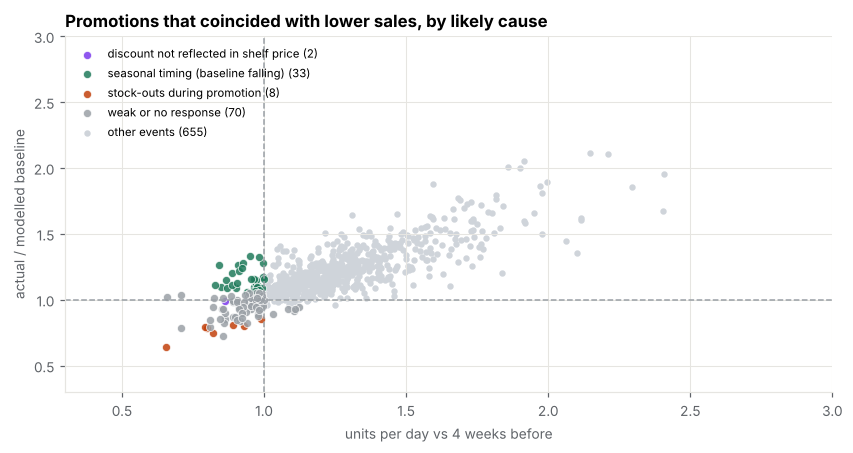

Price-based promotion events: 643; median achieved price change -8.8% (headline median -20%); events with no price fall: 4


,promotion_id,promotion_name,store_id,start,promo_type,discount_pct,vs_pre_period,uplift,price_change,stockout_share
339,PR24-022,Price Drop - Bread & Bakery,S05,2024-07-04,price_discount,0.300,1.008,1.045,0.001,0.000
341,PR24-022,Price Drop - Bread & Bakery,S07,2024-07-04,price_discount,0.300,0.982,1.014,0.002,0.000
741,PR25-043,Price Drop - Personal Care,S05,2025-10-30,price_discount,0.250,0.864,0.988,-0.007,0.000
743,PR25-043,Price Drop - Personal Care,S07,2025-10-30,price_discount,0.250,1.116,1.106,-0.003,0.000


In [25]:
# Occasions when promotions coincide with lower sales: diagnose each case
low = ev[(ev.vs_pre_period < 1) | (ev.uplift < 0.95)].copy()
def diagnose(r):
    if r.stockout_share >= 0.3:
        return "stock-outs during promotion"
    if r.promo_type in ("price_discount", "multibuy") and r.price_change > -0.01:
        return "discount not reflected in shelf price"
    if r.uplift >= 1.05 and r.vs_pre_period < 1:
        return "seasonal timing (baseline falling)"
    return "weak or no response"
low["diagnosis"] = low.apply(diagnose, axis=1)
diag = low.diagnosis.value_counts().to_frame("events")
display(diag)
cols = ["promotion_id", "promotion_name", "store_id", "start", "promo_type", "discount_pct", "vs_pre_period", "uplift", "price_change",
        "stockout_share", "diagnosis"]
display(low.sort_values("vs_pre_period")[cols].head(15).round(3))
display(low[low.diagnosis == "discount not reflected in shelf price"][cols].round(3))

fig, ax = plt.subplots(figsize=(9, 4.2))
colors = {"stock-outs during promotion": ORANGE, "discount not reflected in shelf price": "#7c3aed",
          "seasonal timing (baseline falling)": GREEN, "weak or no response": GREY}
for k, g in low.groupby("diagnosis"):
    ax.scatter(g.vs_pre_period, g.uplift, s=28, color=colors[k], label=f"{k} ({len(g)})", alpha=0.85, edgecolor="white", lw=0.5)
ok = ev.drop(low.index)
ax.scatter(ok.vs_pre_period, ok.uplift, s=10, color="#cfd4da", label=f"other events ({len(ok)})", zorder=0)
ax.axhline(1, color=GREY, lw=1, ls="--"); ax.axvline(1, color=GREY, lw=1, ls="--")
ax.set_xlabel("units per day vs 4 weeks before"); ax.set_ylabel("actual / modelled baseline")
ax.set_xlim(0.3, 3); ax.set_ylim(0.3, 3)
ax.set_title("Promotions that coincided with lower sales, by likely cause")
ax.legend(fontsize=7.5, loc="upper left")
save(fig, "11_promo_lower_sales_diagnosis")
low.to_csv(RESULTS / "promotions_with_lower_sales.csv", index=False)
# Execution check across ALL price-based events (not only the low-sales ones): did the shelf price actually fall?
priced = ev[ev.promo_type != "display_feature"]
noexec = priced[priced.price_change > -0.01]
print(f"Price-based promotion events: {len(priced)}; median achieved price change {priced.price_change.median():.1%} "
      f"(headline median {-priced.discount_pct.median():.0%}); events with no price fall: {len(noexec)}")
display(noexec[cols[:-1]].round(3))
M["noexec_events"] = noexec[["promotion_id", "store_id", "promotion_name", "uplift"]].round(3).values.tolist()
M["median_price_change_priced"] = round(float(priced.price_change.median()), 3)
M["low_events"] = int(len(low)); M["low_diagnosis"] = diag.events.to_dict()
M["exec_fail_cases"] = low.loc[low.diagnosis == "discount not reflected in shelf price", ["promotion_id", "store_id"]].values.tolist()

**Yes - 113 of 768 events (15%) coincided with lower sales**, either below the 4 weeks before or below the modelled baseline. The causes are diagnosable:

| Cause | Events | Examples |
|---|---|---|
| Seasonal timing | 33 | Price drops on rice and cooking oils in early January sold less than in December, yet beat their January baseline |
| Stock-outs during the promotion | 8 | *Ramadan Staples Saver - Rice 2024* at Wuse (S04) had stock-outs on 86% of days and sold 35% less than before; the same promotion at Kano (S07) |
| Discount not reflected at the shelf | 2 in this group, 4 across all events | The average price did not fall in PR24-022 (bread) and PR25-043 (personal care) at **S05 and S07**; the same two stores twice points to a pricing-execution process gap |
| Weak or no response | 70 | Mostly small families in low-response stores |

**Implication:** judging promotions on before/after sales would wrongly condemn the January promotions and miss the execution and supply failures. Each promotion needs a stock and price check before launch.

## 9. Objective 4 - Demand across stores and product categories
### 9.1 Product mix by store and format
The mix index is a store's share of units in a family divided by the chain's share: 1.2 means the family is 20% more important in that store than in the chain overall.

In [26]:
# Family mix index: a store's share of a family relative to the chain's share (1.0 = same mix as the chain)
mix = td.pivot_table(index="family_name", columns="store_id", values="units_sold", aggfunc="sum")
mix_share = mix / mix.sum()
mix_idx = mix_share.div(mix.sum(axis=1) / mix.sum().sum(), axis=0)
display(mix_idx.round(2))
fmt = td.groupby(["store_format"]).apply(lambda g: pd.Series({
    "stores": g.store_id.nunique(), "units_per_store_day": g.units_sold.sum() / g[["store_id", "sale_date"]].drop_duplicates().shape[0],
    "value_per_sqm_day": g.sales_value_ngn.sum() / (g[["store_id", "sale_date"]].drop_duplicates().merge(stores[["store_id", "sales_area_sqm"]]).sales_area_sqm.sum()),
    "promo_median_uplift": ev[ev.store_id.isin(g.store_id.unique())].uplift.median()}))
display(fmt.round(2))
M["mix_index_highlights"] = {s: mix_idx[s].round(2).sort_values(ascending=False).head(2).to_dict() for s in mix_idx.columns}

store_id,S01,S02,S03,S04,S05,S06,S07,S08
family_name,,,,,,,,
"Beer, Wine & Spirits",1.300,1.070,1.160,1.080,1.350,0.930,NaN,1.050
Bread & Bakery,1.020,0.990,0.980,1.000,1.010,0.950,0.990,1.270
Breakfast & Hot Beverages,1.140,0.950,0.950,0.970,0.960,0.940,1.070,0.920
Cooking Oils & Seasonings,0.970,0.960,0.940,0.970,0.940,1.060,1.250,0.560
Dairy & Eggs,1.230,0.950,0.950,0.960,0.970,0.920,0.970,0.910
Fresh Produce,1.030,1.010,0.990,1.000,0.940,0.980,1.010,1.000
Frozen Meat & Fish,1.030,1.000,0.980,1.100,1.170,0.990,0.810,0.480
Household Cleaning,1.010,1.010,0.990,1.030,1.030,1.000,0.980,0.670
Noodles & Pasta,0.700,1.030,1.080,1.010,0.980,1.160,1.170,0.960


,stores,units_per_store_day,value_per_sqm_day,promo_median_uplift
store_format,,,,
express,1.000,"1,441.610","4,782.040",1.110
hypermarket,2.000,"5,713.350","3,016.970",1.150
supermarket,5.000,"3,732.330","3,600.150",1.200


**Each store has a distinct mix:**
- **Lekki:** over-indexes on beer (1.30), personal care (1.25) and dairy (1.23) and under-indexes on noodles (0.70), an affluent profile.
- **Kano:** over-indexes on rice (1.27), oils (1.25) and noodles (1.17).
- **Port Harcourt:** over-indexes on beer (1.35) and frozen (1.17).
- **Ajah Express:** over-indexes on snacks (1.30), bread (1.27) and soft drinks (1.19), and sells little rice (0.42) or frozen (0.48), a top-up convenience basket.

**By format:**
- **Express:** highest sales per sqm, weakest promotion response.
- **Supermarkets:** strongest promotion response (median 1.20).

**Implication:** ranging, space and promotions should follow each store's mix rather than a chain template.

### 9.2 Store events: competitor opening, refurbishment and a new store
Each affected store is compared with the like-for-like stores over the same periods (ratio of ratios), so that chain-wide seasonality cancels out.

S04 Wuse after the competitor opened (Jul-Oct vs Mar-May 2024, relative to other stores): -9.4%
S03 Surulere after refurbishment (Sep-Nov vs May-Jul 2024, relative to other stores): +13.8%


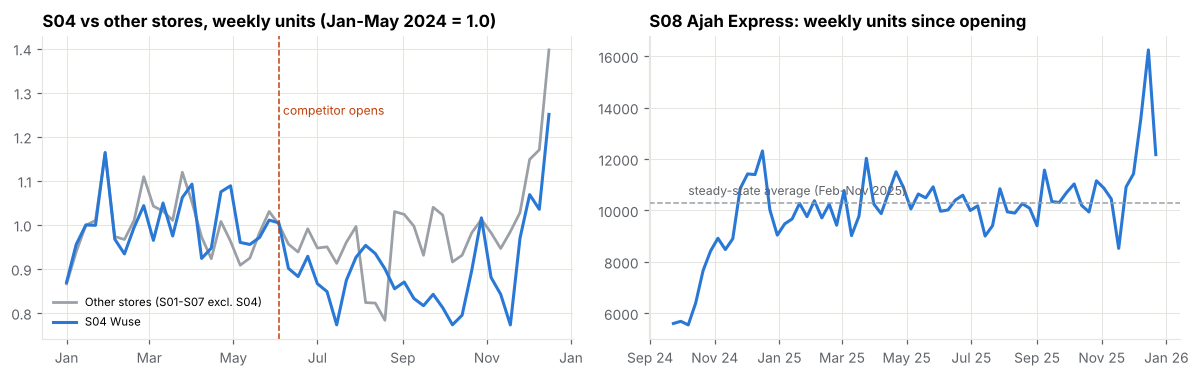

In [27]:
# Store events: compare the affected store with the rest of the chain (difference in ratios) around each event
def rel_change(store, before, after, same_families=True):
    fams_s = td.loc[td.store_id == store, "family_id"].unique()
    d = td[td.family_id.isin(fams_s) & ~td.store_id.isin(["S08"] if store != "S08" else [])]
    a = d[d.store_id == store]; o = d[(d.store_id != store) & d.store_id.isin(lfl_stores)]
    f = lambda x, w: x[x.sale_date.between(*w)].groupby("sale_date").units_adj.sum().mean()
    return (f(a, after) / f(a, before)) / (f(o, after) / f(o, before)) - 1

comp = rel_change("S04", ("2024-03-04", "2024-05-26"), ("2024-07-15", "2024-10-06"))
refurb = rel_change("S03", ("2024-05-06", "2024-07-28"), ("2024-09-09", "2024-12-01"))
print(f"S04 Wuse after the competitor opened (Jul-Oct vs Mar-May 2024, relative to other stores): {comp:+.1%}")
print(f"S03 Surulere after refurbishment (Sep-Nov vs May-Jul 2024, relative to other stores): {refurb:+.1%}")

s08 = td[td.store_id == "S08"].groupby("week_start").units_sold.sum()
s08_week = s08.iloc[1:-1]
steady = s08_week.loc["2025-02-03":"2025-11-24"].mean()
weeks_to_90 = int((s08_week.rolling(3).mean() >= 0.9 * steady).values.argmax())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
w = td[td.store_id.isin(lfl_stores)].copy()
w["grp"] = np.where(w.store_id == "S04", "S04 Wuse", "Other stores")
ww = w[w.week_start.between("2024-01-01", "2024-12-16")].groupby(["week_start", "grp"]).units_adj.sum().unstack()
ww = ww / ww.loc[:"2024-05-27"].mean()
axes[0].plot(ww.index, ww["Other stores"], color=GREY, lw=1.8, label="Other stores (S01-S07 excl. S04)")
axes[0].plot(ww.index, ww["S04 Wuse"], color=BLUE, lw=2, label="S04 Wuse")
axes[0].axvline(pd.Timestamp("2024-06-03"), color=ORANGE, lw=1, ls="--"); axes[0].text(pd.Timestamp("2024-06-06"), 1.25, "competitor opens", color=ORANGE, fontsize=8)
axes[0].set_title("S04 vs other stores, weekly units (Jan-May 2024 = 1.0)"); axes[0].legend(fontsize=7.5, loc="lower left")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[1].plot(s08_week.index, s08_week.values, color=BLUE, lw=2)
axes[1].axhline(steady, color=GREY, ls="--", lw=1); axes[1].text(s08_week.index[2], steady * 1.03, "steady-state average (Feb-Nov 2025)", color=MUTED, fontsize=8)
axes[1].set_title("S08 Ajah Express: weekly units since opening"); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.tight_layout()
save(fig, "12_store_events")
M["s04_competitor_effect"] = round(comp * 100, 1); M["s03_refurb_effect"] = round(refurb * 100, 1); M["s08_weeks_to_90pct"] = weeks_to_90

**Store events (each compared with the other like-for-like stores over the same weeks):**
- **Competitor opening (S04 Wuse):** Wuse lost about **9% of volume** in the four months after the competitor opened. The loss persists rather than recovering.
- **Refurbishment (S03 Surulere):** sales were about **14% higher** in the three months after the refurbishment than before.
- **New store (S08 Ajah Express):** reached 90% of its steady weekly volume within about **9 weeks** of opening.

These are useful planning benchmarks for future refurbishments and openings, though each rests on a single event.

## 10. Objective 5 - Forecasting future sales

### 10.1 Design
- **Target:** daily units per store-family (103 series), the level at which stores order. Bulk days are replaced by the local median because B2B orders are not shelf demand. Stock-out days are excluded from training and scoring because sales on those days understate demand.
- **Known future inputs:** calendar, festivals, planned promotions. Stock-outs are not used as inputs because they are not known in advance.
- **Leakage control:** every lag feature is at least as old as the forecast horizon. A 28-day forecast only uses sales at least 28 days old, and the 91-day model only uses sales at least 91 days old.

**Methods compared:**

| Method | Idea |
|---|---|
| Seasonal naive (last week) | Same weekday last week |
| 4-week weekday average | Mean of the last 4 same weekdays - a typical store manager's rule |
| Last year x level | Same day 52 weeks ago, scaled by the recent level vs last year |
| Holt-Winters ETS | Per-series exponential smoothing, damped trend, weekly seasonality |
| Gradient boosting (28-day lags) | One global model across all series with calendar, promotion and lag features (Poisson loss) |
| Gradient boosting (91-day lags) | Same model restricted to 91-day-old lags, so it can forecast a full quarter ahead |

**Evaluation:**
- **Back-test design:** rolling-origin back-test with 7 origins, 28 days apart, from 9 June to 24 November 2025. Each forecasts 28 days, and the last window covers the run-up to Christmas.
- **Metrics:**
  - WAPE = sum|error| / sum actual, the share of volume mis-forecast;
  - bias = sum(forecast - actual) / sum actual;
  - weekly WAPE, the accuracy that matters for a weekly order.

In [28]:
# ---------------------------------------------------------------------------------------------
# Forecasting set-up: a full panel including the Q1 2026 horizon with known future inputs
# ---------------------------------------------------------------------------------------------
fut_dates = pd.date_range("2026-01-01", "2026-03-31")
fut = series.merge(pd.DataFrame({"sale_date": fut_dates}), how="cross")
fut = fut.merge(stores[["store_id", "open_date", "store_format", "region", "sales_area_sqm"]], on="store_id")
fut = fut.merge(cal.rename(columns={"date": "sale_date"}), on="sale_date", how="left")
fut["day_status"] = "future"
planned = pstores.merge(promos[promos.status == "planned"][["promotion_id", "family_id", "start_date", "end_date"]])
pf = pd.DataFrame([(r.store_id, r.family_id, d, r.promotion_id) for r in planned.itertuples()
                   for d in pd.date_range(r.start_date, r.end_date)], columns=["store_id", "family_id", "sale_date", "promotion_id"])
fut = fut.merge(pf, on=KEY, how="left")
fut["on_promotion"] = fut.promotion_id.notna().astype(int)
fp = pd.concat([panel, fut], ignore_index=True, sort=False)
fp["dow"] = fp.sale_date.dt.dayofweek; fp["doy"] = fp.sale_date.dt.dayofyear; fp["month"] = fp.sale_date.dt.month
fp["north"] = fp.region.isin(["North West", "North Central"]).astype(int)
for name, anchors in (("days_to_xmas", xmas), ("days_to_easter", good_friday + [pd.Timestamp("2026-04-03")]),
                      ("days_to_eid", eid_dates + [pd.Timestamp("2026-03-20")])):
    fp[name] = days_to_next(fp.sale_date, anchors)
fp["promo_type"] = fp.promotion_id.map(pinfo.promo_type).fillna("none")
fp["discount_pct"] = fp.promotion_id.map(pinfo.discount_pct).fillna(0.0)
fp["promo_day"] = np.where(fp.promotion_id.notna(), (fp.sale_date - fp.promotion_id.map(pinfo.start_date)).dt.days + 1, 0)
fp = fp.sort_values(["store_id", "family_id", "sale_date"]).reset_index(drop=True)
# days since the last promotion ended (known in advance from the promotion calendar, incl. planned ones)
allends = pstores.merge(promos[["promotion_id", "family_id", "end_date"]]).rename(columns={"end_date": "sale_date"})[KEY].assign(e=1)
e_flag = fp[KEY].merge(allends, on=KEY, how="left").e.values == 1
fp["last_end"] = fp.sale_date.where(e_flag).groupby([fp.store_id, fp.family_id]).ffill()
fp["days_since_promo"] = (fp.sale_date - fp.last_end).dt.days.clip(upper=60)
fp.loc[fp.on_promotion == 1, "days_since_promo"] = 0
fp["store_age_days"] = (fp.sale_date - fp.open_date).dt.days.clip(upper=730)
for c, src in (("store_c", "store_id"), ("family_c", "family_id"), ("format_c", "store_format"), ("ptype_c", "promo_type")):
    fp[c] = fp[src].astype("category").cat.codes
fp["target"] = np.where(fp.day_status == "trading", fp.units_adj, np.nan)          # bulk-adjusted units
fp["scorable"] = (fp.day_status == "trading") & (fp.stockout_flag == 0) & (fp.bulk_flag == 0)
print(fp.day_status.value_counts().to_dict())


def lag_features(frame, H):
    """Leak-free features: every lag is at least H days old, so they are known H days ahead."""
    g = frame.groupby(["store_id", "family_id"]).target
    out = pd.DataFrame(index=frame.index)
    out[f"dow_mean_lag{H}"] = sum(g.shift(H + 7 * k) for k in range(4)) / 4          # same weekday, 4 weeks
    out[f"roll28_lag{H}"] = g.transform(lambda s: s.shift(H).rolling(28, min_periods=14).mean())
    out["lag364"] = g.shift(364)
    out["roll7_lag364"] = g.transform(lambda s: s.shift(361).rolling(7, min_periods=4).mean())
    out["yoy_level"] = (out[f"roll28_lag{H}"] / g.transform(lambda s: s.shift(H + 364).rolling(28, min_periods=14).mean())).replace([np.inf, -np.inf], np.nan)
    return out


CAL_FEATS = ["dow", "month", "doy", "day_of_month", "is_weekend", "is_public_holiday", "is_ramadan", "is_payday_window",
             "is_back_to_school", "days_to_xmas", "days_to_easter", "days_to_eid", "north"]
PROMO_FEATS = ["on_promotion", "ptype_c", "discount_pct", "promo_day", "days_since_promo"]
ID_FEATS = ["store_c", "family_c", "format_c", "sales_area_sqm", "store_age_days"]
LAGS = {H: lag_features(fp, H) for H in (28, 91)}
print({H: list(v.columns) for H, v in LAGS.items()})

{'trading': 104118, 'future': 9270, 'store not yet open': 8112, 'chain closed (25 Dec)': 296, 'refurbishment closure': 273, 'pos outage': 89}


{28: ['dow_mean_lag28', 'roll28_lag28', 'lag364', 'roll7_lag364', 'yoy_level'], 91: ['dow_mean_lag91', 'roll28_lag91', 'lag364', 'roll7_lag364', 'yoy_level']}


### 10.2 Rolling-origin back-test

In [29]:
# Rolling-origin back-test: 7 origins, 28-day horizon each (Jun-Dec 2025, includes the pre-Christmas peak)
ORIGINS = pd.date_range("2025-06-09", periods=7, freq="28D")
H = 28
hist = fp[fp.day_status != "future"]
hist_series = {k: g.set_index("sale_date").target for k, g in hist.groupby(["store_id", "family_id"])}


def gbm_fit_predict(train_idx, test_idx, Hmin):
    X = pd.concat([fp[CAL_FEATS + PROMO_FEATS + ID_FEATS], LAGS[Hmin]], axis=1)
    m = HistGradientBoostingRegressor(loss="poisson", max_iter=500, learning_rate=0.05, max_leaf_nodes=48,
                                      min_samples_leaf=40, l2_regularization=1.0, random_state=SEED,
                                      categorical_features=[X.columns.get_loc(c) for c in ("store_c", "family_c", "format_c", "ptype_c")])
    m.fit(X.loc[train_idx], fp.loc[train_idx, "target"])
    return m.predict(X.loc[test_idx]), m, X


def ets_forecast(y, h):
    y = y.interpolate(limit_direction="both").clip(lower=0)
    try:
        r = ExponentialSmoothing(y.values, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7,
                                 initialization_method="estimated").fit()
        return np.clip(r.forecast(h), 0, None)
    except Exception:
        return np.repeat(y.iloc[-28:].mean(), h)


preds = []
t0 = time.time()
for k, origin in enumerate(ORIGINS):
    end = origin + pd.Timedelta(days=H - 1)
    train_idx = fp.index[(fp.sale_date < origin) & fp.scorable]
    test_mask = fp.sale_date.between(origin, end) & (fp.day_status == "trading")
    test_idx = fp.index[test_mask]
    out = fp.loc[test_idx, KEY + ["units_sold", "target", "scorable", "family_name", "on_promotion"]].copy()
    out["fold"], out["origin"] = k + 1, origin
    out["h"] = (out.sale_date - origin).dt.days + 1
    # global gradient-boosting models (28-day and 91-day minimum lag)
    out["gbm28"], model28, X28 = gbm_fit_predict(train_idx, test_idx, 28)
    out["gbm91"], _, _ = gbm_fit_predict(train_idx, test_idx, 91)
    # baselines and per-series ETS, using history strictly before the origin
    sn7, ma4, sny, etsf = [], [], [], []
    for (s, f), g in out.groupby(["store_id", "family_id"]):
        h_ser = hist_series[(s, f)].loc[:origin - pd.Timedelta(days=1)]
        last28 = h_ser.iloc[-28:]
        prof4 = last28.groupby(last28.index.dayofweek).mean()
        prof1 = h_ser.iloc[-7:].groupby(h_ser.iloc[-7:].index.dayofweek).mean().reindex(range(7)).fillna(prof4)
        ly = h_ser.reindex(g.sale_date - pd.Timedelta(days=364)).values
        ly_level = h_ser.loc[origin - pd.Timedelta(days=364 + 28): origin - pd.Timedelta(days=365)].mean()
        ratio = last28.mean() / ly_level if ly_level and ly_level > 0 else np.nan
        e = ets_forecast(h_ser.iloc[-400:], H)
        dd = g.sale_date.dt.dayofweek.values
        sn7.append(pd.Series(prof1.reindex(dd).values, index=g.index))
        ma4.append(pd.Series(prof4.reindex(dd).values, index=g.index))
        sny.append(pd.Series(ly * ratio, index=g.index))
        etsf.append(pd.Series(e[(g.sale_date - origin).dt.days.values], index=g.index))
    out["seasonal_naive_7"] = pd.concat(sn7); out["weekday_avg_4w"] = pd.concat(ma4)
    out["seasonal_naive_364"] = pd.concat(sny); out["ets"] = pd.concat(etsf)
    out["seasonal_naive_364"] = out.seasonal_naive_364.fillna(out.weekday_avg_4w)    # no last-year data (new store)
    preds.append(out)
    print(f"fold {k + 1}: origin {origin.date()}, train rows {len(train_idx):,}, test rows {len(test_idx):,}, {time.time() - t0:.0f}s")
bt = pd.concat(preds)
METHODS = ["seasonal_naive_7", "weekday_avg_4w", "seasonal_naive_364", "ets", "gbm91", "gbm28"]
assert bt[METHODS].notna().all().all()
bt.to_csv(RESULTS / "backtest_predictions.csv.gz", index=False, compression="gzip")

fold 1: origin 2025-06-09, train rows 81,698, test rows 2,884, 16s


fold 2: origin 2025-07-07, train rows 84,520, test rows 2,871, 32s


fold 3: origin 2025-08-04, train rows 87,344, test rows 2,884, 51s


fold 4: origin 2025-09-01, train rows 90,183, test rows 2,884, 69s


fold 5: origin 2025-09-29, train rows 93,017, test rows 2,884, 88s


fold 6: origin 2025-10-27, train rows 95,833, test rows 2,884, 105s


fold 7: origin 2025-11-24, train rows 98,667, test rows 2,884, 126s


### 10.3 How accurate are the different methods?

,WAPE,bias,MAE (units/day),weekly WAPE
gbm91,0.207,-0.021,63.165,0.099
gbm28,0.208,-0.026,63.517,0.100
ets,0.237,-0.032,72.248,0.146
weekday_avg_4w,0.251,-0.038,76.548,0.141
seasonal_naive_364,0.298,-0.007,90.897,0.153
seasonal_naive_7,0.305,-0.022,93.013,0.160


,seasonal_naive_7,weekday_avg_4w,seasonal_naive_364,ets,gbm91,gbm28
origin,,,,,,
2025-06-09,0.317,0.235,0.284,0.228,0.209,0.212
2025-07-07,0.290,0.240,0.288,0.218,0.199,0.200
2025-08-04,0.307,0.238,0.285,0.239,0.208,0.208
2025-09-01,0.316,0.244,0.287,0.228,0.207,0.205
2025-09-29,0.306,0.269,0.313,0.248,0.208,0.209
2025-10-27,0.278,0.238,0.319,0.214,0.200,0.200
2025-11-24,0.319,0.285,0.308,0.275,0.217,0.222


Best method: gbm91; better than gbm28 in 52% of series-folds (Wilcoxon p = 5.4e-01)


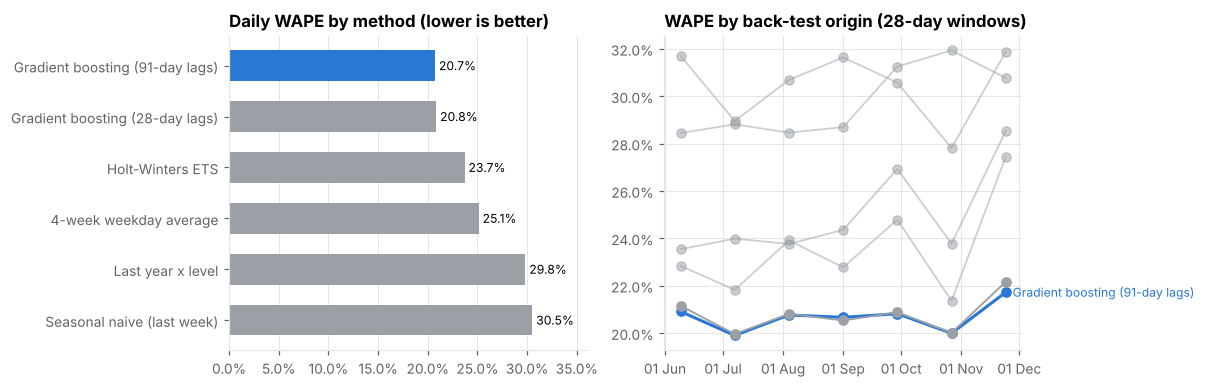

In [30]:
def wape(y, f):
    return np.abs(y - f).sum() / y.sum()


def bias(y, f):
    return (f - y).sum() / y.sum()


sc = bt[bt.scorable]
overall = pd.DataFrame({m: {"WAPE": wape(sc.target, sc[m]), "bias": bias(sc.target, sc[m]),
                            "MAE (units/day)": np.abs(sc.target - sc[m]).mean()} for m in METHODS}).T
# weekly accuracy (what a weekly order needs): sum by series x week within each fold
sc_w = sc.assign(week=(sc.h - 1) // 7).groupby(["fold", "store_id", "family_id", "week"])[["target"] + METHODS].sum()
overall["weekly WAPE"] = [wape(sc_w.target, sc_w[m]) for m in METHODS]
overall = overall.sort_values("WAPE")
display(overall.round(3))
by_fold = pd.DataFrame({m: sc.groupby("origin").apply(lambda g: wape(g.target, g[m])) for m in METHODS})
display(by_fold.round(3))

# Is the best method's advantage consistent? Paired Wilcoxon test over series-fold WAPEs
best, second = overall.index[0], overall.index[1]
pair = sc.groupby(["store_id", "family_id", "fold"]).apply(lambda g: pd.Series({best: wape(g.target, g[best]), second: wape(g.target, g[second])}))
w_stat, w_p = stats.wilcoxon(pair[best], pair[second])
print(f"Best method: {best}; better than {second} in {(pair[best] < pair[second]).mean():.0%} of series-folds (Wilcoxon p = {w_p:.1e})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
o = overall.sort_values("WAPE", ascending=False)
names = {"seasonal_naive_7": "Seasonal naive (last week)", "weekday_avg_4w": "4-week weekday average",
         "seasonal_naive_364": "Last year x level", "ets": "Holt-Winters ETS", "gbm91": "Gradient boosting (91-day lags)",
         "gbm28": "Gradient boosting (28-day lags)"}
axes[0].barh([names[m] for m in o.index], o.WAPE, color=[BLUE if m == best else GREY for m in o.index], height=0.6)
for y, v in enumerate(o.WAPE):
    axes[0].text(v + 0.004, y, f"{v:.1%}", va="center", fontsize=8)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].grid(axis="y", visible=False)
axes[0].set_title("Daily WAPE by method (lower is better)"); axes[0].set_xlim(0, o.WAPE.max() * 1.18)
for m in METHODS:
    axes[1].plot(by_fold.index, by_fold[m], marker="o", lw=2 if m == best else 1.2, color=BLUE if m == best else GREY,
                 alpha=1 if m in (best, second) else 0.5)
axes[1].text(by_fold.index[-1], by_fold[best].iloc[-1], f"  {names[best]}", color=BLUE, fontsize=8, va="center")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title("WAPE by back-test origin (28-day windows)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.tight_layout()
save(fig, "13_forecast_method_comparison")
M["backtest"] = overall.round(4).to_dict("index"); M["best_method"] = best; M["second_method"] = second
M["best_beats_second_share"] = round(float((pair[best] < pair[second]).mean()), 3); M["wilcoxon_p"] = float(f"{w_p:.2e}")
M["fold_wape_best"] = {str(k.date()): round(v, 3) for k, v in by_fold[best].items()}

**Historical data can forecast sales well, and the method matters.**

| Method | Daily WAPE | Weekly WAPE |
|---|---|---|
| Gradient boosting (91-day lags) | **20.7%** | **9.9%** |
| Gradient boosting (28-day lags) | 20.8% | 10.0% |
| Holt-Winters ETS | 23.7% | 14.6% |
| 4-week weekday average | 25.1% | 14.1% |
| Last year x level | 29.8% | 15.3% |
| Seasonal naive (last week) | 30.5% | 16.0% |

- **Against current practice:** the 4-week weekday average is closest to what store managers do today. The model cuts its daily error by about 17% and its weekly error by about 29%.
- **Consistency:** the model's advantage holds in every back-test window (19.9-21.7%). Its hardest window was the run-up to Christmas.
- **The two gradient-boosting variants tie:** there is no significant difference (Wilcoxon p = 0.54). Sales from the last 28 days add nothing beyond the calendar, promotion and longer-run level information. The 91-day version is therefore selected, because one model can forecast the whole quarter from a single origin.
- **Bias:** a small under-forecast of about 2%, which the safety stock must absorb.

### 10.4 Which product families and stores are most predictable?

,WAPE,bias,naive WAPE,improvement_vs_naive
family_name,,,,
Bread & Bakery,0.134,0.002,0.153,0.125
Dairy & Eggs,0.170,0.003,0.185,0.080
Noodles & Pasta,0.181,-0.064,0.247,0.266
Breakfast & Hot Beverages,0.185,-0.013,0.210,0.121
Cooking Oils & Seasonings,0.185,-0.031,0.223,0.167
Household Cleaning,0.186,0.016,0.238,0.217
Personal Care,0.188,-0.022,0.217,0.133
Snacks & Confectionery,0.193,-0.008,0.243,0.206
Rice & Grains,0.222,0.023,0.252,0.120


,WAPE,bias
store_id,,
S03,0.190,-0.012
S01,0.192,-0.042
S04,0.193,-0.018
S06,0.195,-0.002
S02,0.200,-0.032
S07,0.200,-0.018
S08,0.235,-0.004
S05,0.289,-0.003


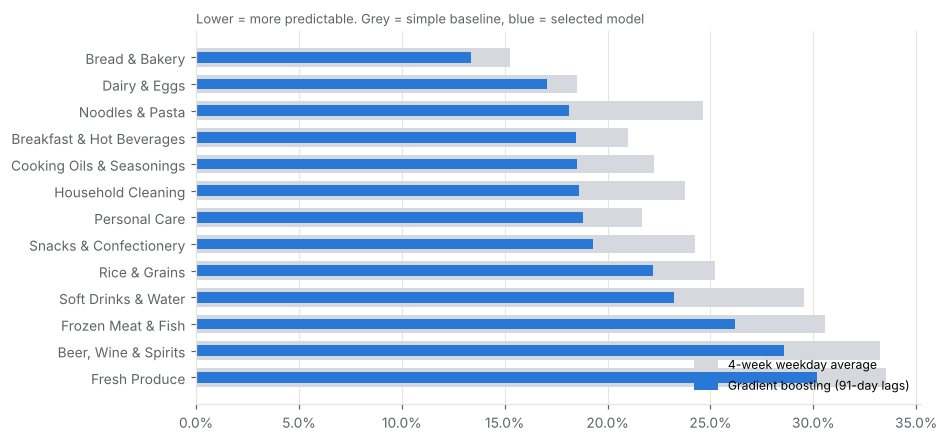

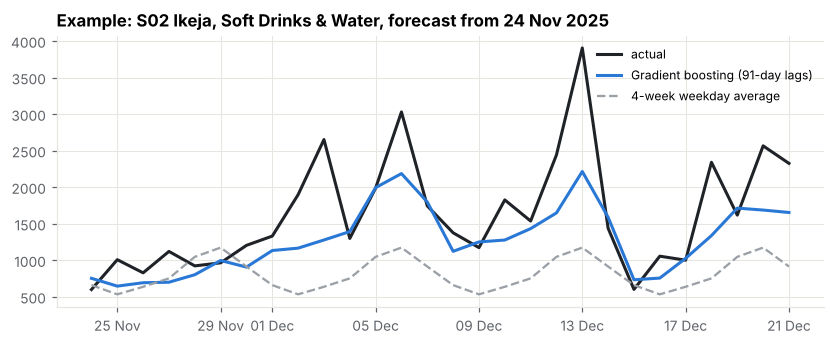

In [31]:
fam_acc = sc.groupby("family_name").apply(lambda g: pd.Series({"WAPE": wape(g.target, g[best]), "bias": bias(g.target, g[best]),
                                                                "naive WAPE": wape(g.target, g.weekday_avg_4w)}))
fam_acc["improvement_vs_naive"] = 1 - fam_acc.WAPE / fam_acc["naive WAPE"]
fam_acc = fam_acc.sort_values("WAPE")
store_acc = sc.groupby("store_id").apply(lambda g: pd.Series({"WAPE": wape(g.target, g[best]), "bias": bias(g.target, g[best])})).sort_values("WAPE")
display(fam_acc.round(3)); display(store_acc.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
d = fam_acc.sort_values("WAPE", ascending=False)
ax.barh(d.index, d["naive WAPE"], color="#d5d9de", height=0.7, label="4-week weekday average")
ax.barh(d.index, d.WAPE, color=BLUE, height=0.4, label=names[best])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.grid(axis="y", visible=False)
ax.set_title("Forecast error by product family (daily WAPE, back-test)")
subtitle(ax, "Lower = more predictable. Grey = simple baseline, blue = selected model")
ax.legend(loc="lower right", fontsize=8)
save(fig, "14_forecast_accuracy_by_family")

# Example series: actual vs forecasts for the December origin
ex = bt[(bt.store_id == "S02") & (bt.family_id == "F09") & (bt.fold == bt.fold.max())]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ex.sale_date, ex.units_sold, color=INK, lw=2, label="actual")
ax.plot(ex.sale_date, ex[best], color=BLUE, lw=2, label=names[best])
ax.plot(ex.sale_date, ex.weekday_avg_4w, color=GREY, lw=1.5, ls="--", label="4-week weekday average")
ax.set_title("Example: S02 Ikeja, Soft Drinks & Water, forecast from 24 Nov 2025"); ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
save(fig, "15_forecast_example")
M["family_wape"] = fam_acc.WAPE.round(3).to_dict(); M["store_wape"] = store_acc.WAPE.round(3).to_dict()
M["family_improvement_vs_naive"] = fam_acc.improvement_vs_naive.round(3).to_dict()

**Most predictable families:** bread (WAPE 13%), dairy (17%), noodles, breakfast and cooking oils (about 18-19%).
**Least predictable:** fresh produce (30%), beer (29%) and frozen (26%).

**Gains over the naive method are largest where promotions matter most:**
- noodles: 27% lower error;
- household cleaning, soft drinks and snacks: about 21-22% lower.

The model knows the promotion calendar; a weekday average does not.

**By store:**
- Port Harcourt (S05, 29%) and Ajah Express (S08, 23.5%) are clearly harder to forecast.
- The other six stores are all within 19-20%.

The example chart shows the model following the pre-Christmas build-up that the weekday average misses, while still under-predicting the sharpest spikes.

### 10.5 What drives the forecast?

In [32]:
# Which inputs drive the selected model? Permutation importance on the last back-test fold (sample of rows)
origin = ORIGINS[-1]
train_idx = fp.index[(fp.sale_date < origin) & fp.scorable]
test_idx = fp.index[fp.sale_date.between(origin, origin + pd.Timedelta(days=27)) & fp.scorable]
Hm = 28 if best == "gbm28" else 91
_, model, X = gbm_fit_predict(train_idx, test_idx, Hm)
samp = np.random.RandomState(SEED).choice(test_idx, size=min(1500, len(test_idx)), replace=False)
pi = permutation_importance(model, X.loc[samp], fp.loc[samp, "target"], n_repeats=3, random_state=SEED, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
display(imp.head(12).round(2).to_frame("MAE increase when shuffled"))
M["top_features"] = imp.head(8).round(2).to_dict()

,MAE increase when shuffled
family_c,55.080
roll28_lag91,35.030
store_c,21.920
dow_mean_lag91,18.740
dow,14.090
days_to_xmas,8.190
ptype_c,4.500
roll7_lag364,1.740
lag364,1.670
sales_area_sqm,1.490


The forecast is driven mainly by:
- what is being sold (family) and where (store);
- the recent level of the series and its weekday profile;
- the weekday itself, the distance to Christmas and the promotion type.

This matches the patterns found in sections 7-8. The model is learning the business's real demand structure rather than noise.

### 10.6 Forecast for Q1 2026
The selected approach is refitted on all history to the end of December 2025:
- **1-28 January:** the 28-day model (operational ordering).
- **Rest of the quarter:** the 91-day model (planning outlook).

Planned Q1 promotions and the Ramadan / Eid al-Fitr timing come from the calendar. The 80% range uses the back-test distribution of actual / forecast ratios by family.

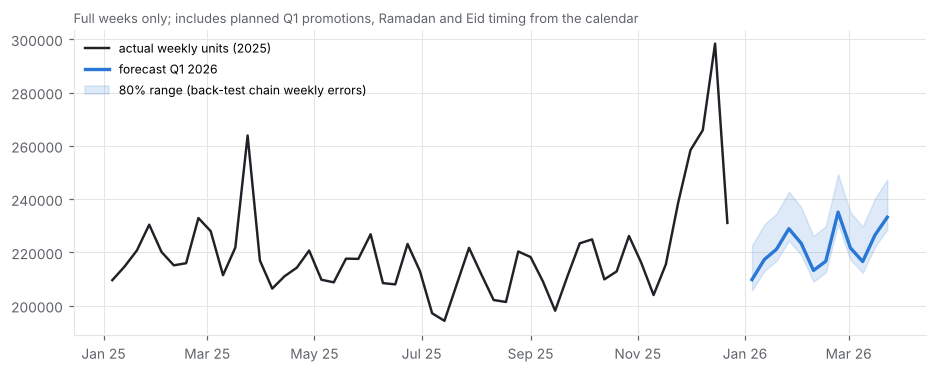

Q1 2026 forecast: 2,842,026 units vs 2,847,700 actual in Q1 2025


In [33]:
# Forward forecast for Q1 2026: 28-day-lag model for 1-28 Jan (operational), 91-day-lag model for the full quarter
train_all = fp.index[(fp.day_status != "future") & fp.scorable]
fut_idx = fp.index[fp.day_status == "future"]
p28, _, _ = gbm_fit_predict(train_all, fut_idx, 28)
p91, _, _ = gbm_fit_predict(train_all, fut_idx, 91)
fc = fp.loc[fut_idx, KEY + ["family_name", "on_promotion", "promotion_id"]].copy()
fc["forecast_gbm28"], fc["forecast_gbm91"] = p28, p91
fc["horizon_day"] = (fc.sale_date - pd.Timestamp("2025-12-31")).dt.days
if best == "gbm91":        # 91-day model is as accurate as the 28-day one and covers the whole quarter from one origin
    fc["forecast_units"], fc["model_used"] = fc.forecast_gbm91, "gbm91"
else:                      # otherwise use the 28-day model while its lags are available
    fc["forecast_units"] = np.where(fc.horizon_day <= 28, fc.forecast_gbm28, fc.forecast_gbm91)
    fc["model_used"] = np.where(fc.horizon_day <= 28, "gbm28", "gbm91")
fc.loc[fc.horizon_day > 28, "forecast_gbm28"] = np.nan      # 28-day model lags are not available beyond 28 days
# 80% interval from back-test relative errors of the matching model, by family
for m, col in (("gbm28", "rel28"), ("gbm91", "rel91")):
    r = (sc.target / sc[m]).replace([np.inf, -np.inf], np.nan)
    q = r.groupby(sc.family_id).quantile([0.1, 0.9]).unstack()
    fc.loc[fc.model_used == m, "p10"] = fc.loc[fc.model_used == m, "forecast_units"] * fc.loc[fc.model_used == m, "family_id"].map(q[0.1])
    fc.loc[fc.model_used == m, "p90"] = fc.loc[fc.model_used == m, "forecast_units"] * fc.loc[fc.model_used == m, "family_id"].map(q[0.9])
fc = fc.round({"forecast_gbm28": 1, "forecast_gbm91": 1, "forecast_units": 1, "p10": 1, "p90": 1})
fc.to_csv(RESULTS / "forecast_q1_2026.csv", index=False, date_format="%Y-%m-%d")

hist_w = td[td.sale_date >= "2025-01-01"].groupby("week_start").units_sold.sum()
fw = fc.assign(week_start=fc.sale_date - pd.to_timedelta(fc.sale_date.dt.dayofweek, unit="D")).groupby("week_start")[["forecast_units"]].sum()
# chain-level weekly band from the back-test: distribution of actual / forecast for chain weekly totals (full weeks)
cw = sc.assign(week=(sc.h - 1) // 7).groupby(["fold", "week"])[["target", best]].sum()
wr = cw.target / cw[best]
fw["p10"], fw["p90"] = fw.forecast_units * wr.quantile(0.1), fw.forecast_units * wr.quantile(0.9)
M["chain_weekly_ratio_p10_p90"] = [round(wr.quantile(0.1), 3), round(wr.quantile(0.9), 3)]
ly = td[td.sale_date.between("2025-01-01", "2025-03-31")].groupby("week_start").units_sold.sum()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hist_w.index[1:-1], hist_w.values[1:-1], color=INK, lw=1.6, label="actual weekly units (2025)")
ax.plot(fw.index[1:-1], fw.forecast_units[1:-1], color=BLUE, lw=2.2, label="forecast Q1 2026")
ax.fill_between(fw.index[1:-1], fw.p10[1:-1], fw.p90[1:-1], color=BLUE, alpha=0.15, label="80% range (back-test chain weekly errors)")
ax.set_title("Chain weekly units: 2025 actuals and the Q1 2026 forecast")
subtitle(ax, "Full weeks only; includes planned Q1 promotions, Ramadan and Eid timing from the calendar")
ax.legend(fontsize=8, loc="upper left"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
save(fig, "16_q1_2026_forecast")
q1_total = fc.forecast_units.sum(); q1_ly = ly.sum()
print(f"Q1 2026 forecast: {q1_total:,.0f} units vs {td[td.sale_date.between('2025-01-01', '2025-03-31')].units_sold.sum():,.0f} actual in Q1 2025")
M["q1_2026_forecast_units"] = int(q1_total)
M["q1_2025_actual_units"] = int(td[td.sale_date.between("2025-01-01", "2025-03-31")].units_sold.sum())
M["forecast_rows"] = len(fc)

**Q1 2026 forecast:** 2.84 million units, in line with Q1 2025 (2.85 million). That is consistent with the flat like-for-like volume trend.

| Month | Forecast units |
|---|---|
| January | 0.96m |
| February | 0.89m |
| March | 0.99m |

March is lifted by Ramadan and Eid al-Fitr (around 20 March) and the planned promotions.

- **Uncertainty at chain level:** in the back-test, actual chain weekly units fell between 0.98x and 1.06x the forecast in 80% of weeks.
- **Uncertainty at series level:** much wider. The file `outputs/results/forecast_q1_2026.csv` gives daily forecasts with a p10-p90 range for every store-family.

## 11. Objective 6 - Turning forecasts into replenishment decisions

Each series is reviewed every *R* days and receives deliveries *L* days after ordering, so stock must cover the **protection period P = L + R**. The steps are:
1. **Safety stock.** Under a periodic-review order-up-to policy, safety stock = z x sigma_P. Here z = 1.88 for the 97% service-level target, and sigma_P is the standard deviation of the **cumulative forecast error over P days**, measured directly in the back-test, not assumed.
2. **Order-up-to level.** Forecast demand over P plus safety stock, rounded up to full cases. The order quantity is the order-up-to level minus the inventory position, which the store system holds; inventory data is not in this dataset.
3. **Comparison.** The result is compared with today's flat 2-day rule and with the safety stock a naive forecast would require.

,series
policy_gap,
about right,53
over-stocked today,37
under-protected today,13


family_name,"Beer, Wine & Spirits",Rice & Grains,Personal Care,Cooking Oils & Seasonings,Frozen Meat & Fish,Household Cleaning,Breakfast & Hot Beverages,Noodles & Pasta,Soft Drinks & Water,Snacks & Confectionery,Dairy & Eggs,Fresh Produce,Bread & Bakery
P,9.860,10.380,10.380,10.380,6.750,10.380,10.380,10.380,6.380,10.380,5.750,2.000,2.000
recommended_ss_days,2.370,2.250,1.980,1.980,1.970,1.930,1.910,1.840,1.750,1.610,1.060,1.050,0.480


Series needing more cover than today's 2-day rule had more historical stock-outs: Spearman rho = 0.03 (p = 7.5e-01)
Safety stock needed with the selected model vs the 4-week weekday average forecast: 41.8% lower in total
Series where the order-up-to level exceeds shelf life: 0


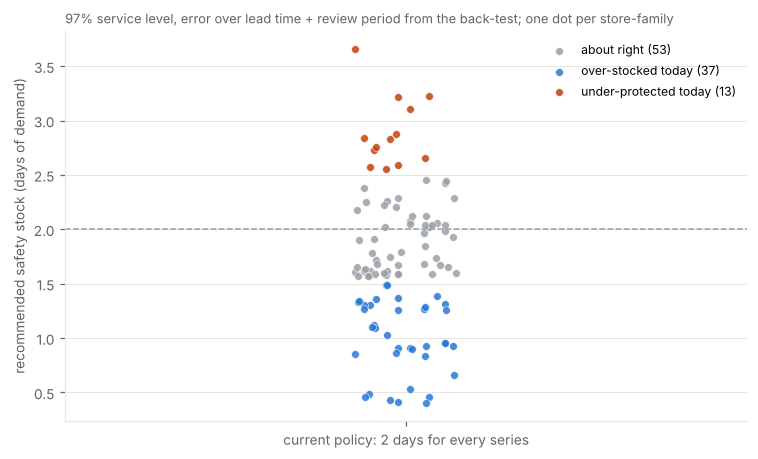

In [34]:
# Safety stock from back-test error over each series' protection period (lead time + review period)
Z = stats.norm.ppf(0.97)                                     # management's 97% service-level target
rp = repl.copy()
rp["P"] = rp.supplier_lead_time_days + rp.review_period_days


def sigma_P(g, col, P):
    """SD of cumulative forecast error over P consecutive days (within each 28-day back-test window)."""
    sums = []
    for _, w in g.groupby("fold"):
        e = (w.target - w[col]).values
        if len(e) >= P:
            c = np.convolve(e, np.ones(P), mode="valid")
            sums.extend(c[::max(1, P // 2)])
    return np.std(sums, ddof=1) if len(sums) > 3 else np.nan


rows = []
for r in rp.itertuples():
    g = sc[(sc.store_id == r.store_id) & (sc.family_id == r.family_id)].sort_values("sale_date")
    rows.append(dict(store_id=r.store_id, family_id=r.family_id, sigma_P_model=sigma_P(g, best, r.P),
                     sigma_P_naive=sigma_P(g, "weekday_avg_4w", r.P), hist_stockout_rate=td[(td.store_id == r.store_id) & (td.family_id == r.family_id)].stockout_flag.mean()))
ss = rp.merge(pd.DataFrame(rows))
jan = fc[fc.horizon_day <= 28].groupby(["store_id", "family_id"]).forecast_units.mean().rename("avg_daily_forecast")
ss = ss.merge(jan.reset_index())
ss["family_name"] = ss.family_id.map(fam_attr.family_name)
ss["current_ss_units"] = ss.current_safety_stock_days * ss.avg_daily_forecast
ss["recommended_ss_units"] = Z * ss.sigma_P_model
ss["naive_ss_units"] = Z * ss.sigma_P_naive
ss["recommended_ss_days"] = ss.recommended_ss_units / ss.avg_daily_forecast
ss["cycle_demand_P"] = ss.avg_daily_forecast * ss.P
ss["order_up_to_units"] = np.ceil((ss.cycle_demand_P + ss.recommended_ss_units) / ss.case_pack_units) * ss.case_pack_units
ss["cover_days_at_order_up_to"] = ss.order_up_to_units / ss.avg_daily_forecast
ss["shelf_life_risk"] = ss.cover_days_at_order_up_to > ss.shelf_life_days
ss["policy_gap"] = np.select([ss.recommended_ss_days > ss.current_safety_stock_days * 1.25, ss.recommended_ss_days < ss.current_safety_stock_days * 0.75],
                             ["under-protected today", "over-stocked today"], "about right")
display(ss.policy_gap.value_counts().to_frame("series"))
display(ss.groupby("family_name")[["P", "recommended_ss_days"]].mean().sort_values("recommended_ss_days", ascending=False).round(2).T)
rho, p = stats.spearmanr(ss.recommended_ss_days - ss.current_safety_stock_days, ss.hist_stockout_rate)
print(f"Series needing more cover than today's 2-day rule had more historical stock-outs: Spearman rho = {rho:.2f} (p = {p:.1e})")
saving = 1 - ss.recommended_ss_units.sum() / ss.naive_ss_units.sum()
print(f"Safety stock needed with the selected model vs the 4-week weekday average forecast: {saving:.1%} lower in total")
print("Series where the order-up-to level exceeds shelf life:", int(ss.shelf_life_risk.sum()))
ss.round(2).to_csv(RESULTS / "replenishment_policy_by_series.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.6))
cmap = {"under-protected today": ORANGE, "over-stocked today": BLUE, "about right": GREY}
for k, g in ss.groupby("policy_gap"):
    ax.scatter(g.current_safety_stock_days + np.random.RandomState(1).uniform(-0.15, 0.15, len(g)), g.recommended_ss_days,
               s=26, color=cmap[k], label=f"{k} ({len(g)})", alpha=0.85, edgecolor="white", lw=0.4)
ax.axhline(2, color=GREY, ls="--", lw=1)
ax.set_xlim(1, 3); ax.set_xticks([2]); ax.set_xticklabels(["current policy: 2 days for every series"])
ax.set_ylabel("recommended safety stock (days of demand)")
ax.set_title("Recommended safety stock vs the current flat 2-day rule")
subtitle(ax, "97% service level, error over lead time + review period from the back-test; one dot per store-family")
ax.legend(fontsize=8, loc="upper right"); ax.grid(axis="x", visible=False)
save(fig, "17_safety_stock_vs_policy")
M["policy_gap_counts"] = ss.policy_gap.value_counts().to_dict(); M["ss_stockout_spearman"] = round(rho, 2)
M["ss_saving_vs_naive_pct"] = round(saving * 100, 1); M["shelf_life_risk_series"] = int(ss.shelf_life_risk.sum())
M["ss_days_by_family"] = ss.groupby("family_name").recommended_ss_days.mean().round(2).to_dict()

**Forecasts change the replenishment policy in both directions.**

| Verdict on today's 2-day rule | Series | Where |
|---|---|---|
| About right | 53 | - |
| More than needed (over-stocked) | 37 | All 8 bread series and most dairy and fresh produce. Local daily delivery means 0.5-1 day of cover is enough, so the rule ties up perishable stock and risks waste |
| Too little (under-protected) | 13 | Mostly Port Harcourt (7 of its 13 series) and Kano (3). Lead times of 5-7 days and higher volatility call for up to 3.7 days, especially for beer, frozen, rice and household |

**Totals:**
- **Safety stock:** recommended 48.7k units against 60.6k under the current rule, a 20% reduction while protecting the series that need it.
- **Value of the better forecast:** with the naive forecast the same service level would need 83.6k units. The selected model needs **42% less safety stock**.
- **Shelf life:** no recommended order-up-to level exceeds the product's shelf life.

**Historical stock-outs are not explained by the safety-stock gap** (Spearman 0.03). Combined with the promotion findings, this suggests many stock-outs come from supply failures (deliveries, promotion stock), not from forecast error. Supply reliability needs its own fix.

### 11.1 Which stores require additional attention?
Four indicators are combined using percentile ranks, equally weighted:
- forecast error;
- baseline volatility;
- historical stock-out rate;
- safety stock required.

In [35]:
# Stores that need attention: combine forecast error, baseline volatility, stock-out rate and safety stock needed
att = pd.DataFrame({
    "forecast_WAPE": store_acc.WAPE,
    "baseline_CV": store_vol,
    "stockout_rate": td.groupby("store_id").stockout_flag.mean(),
    "safety_stock_days": ss.groupby("store_id").recommended_ss_days.mean(),
})
att["attention_score"] = att.rank(pct=True).mean(axis=1)
att = att.join(stores.set_index("store_id")[["store_name", "store_format"]]).sort_values("attention_score", ascending=False)
display(att.round(3))
M["attention_rank"] = att.index.tolist(); M["attention_table"] = att.drop(columns=["store_name", "store_format"]).round(3).to_dict("index")

,forecast_WAPE,baseline_CV,stockout_rate,safety_stock_days,attention_score,store_name,store_format
store_id,,,,,,,
S05,0.289,0.332,0.025,2.364,0.969,Basketline GRA Port Harcourt,supermarket
S07,0.200,0.243,0.030,1.910,0.844,Basketline Nassarawa Kano,supermarket
S08,0.235,0.294,0.022,1.561,0.750,Basketline Ajah Express,express
S02,0.200,0.232,0.014,1.701,0.531,Basketline Ikeja,hypermarket
S06,0.195,0.242,0.011,1.466,0.469,Basketline Ring Road Ibadan,supermarket
S04,0.193,0.236,0.011,1.798,0.438,Basketline Wuse,supermarket
S03,0.190,0.242,0.012,1.409,0.344,Basketline Surulere,supermarket
S01,0.192,0.232,0.009,1.403,0.156,Basketline Lekki,hypermarket


**Stores needing additional attention:**
1. **S05 Port Harcourt:** highest forecast error (29%), highest volatility, 2.5% stock-out rate, 5-day lead time.
2. **S07 Kano:** highest stock-out rate (3.0%) and a 7-day lead time.
3. **S08 Ajah Express:** short history and higher forecast error (24%).

The other five stores are similar and well served by the forecast.

## 12. Quality assurance

In [36]:
# Quality assurance: reconciliations and integrity checks on what the analysis used and produced
qa = {
    "raw rows = clean + removed (duplicates, superseded, S99)": len(raw) == len(clean) + cleaning_log.set_index("issue").rows_affected[
        ["Exact duplicate rows", "Same date-store-family loaded twice with different values", "Rows for store S99 (not in store master; 3 days, 1-5 units per row)"]].sum(),
    "no duplicate keys in clean data": not clean.duplicated(KEY).any(),
    "every missing panel day explained": (panel.day_status != "unexplained gap").all(),
    "clean CSV units = analysis units": pd.read_csv(PROC / "basketline_sales_daily_clean.csv", usecols=["units_sold"]).units_sold.sum() == td.units_sold.sum(),
    "category totals reconcile to grand total": cat_tbl.units.sum() == td.units_sold.sum(),
    "store totals reconcile to grand total": st_tbl.units.sum() == td.units_sold.sum(),
    "back-test horizons never exceed the 28-day minimum lag (no leakage)": int(bt.h.max()) <= 28,
    "back-test predictions complete": bt[METHODS].notna().all().all(),
    "forecast covers 103 series x 90 days": len(fc) == len(series) * 90,
    "forecasts non-negative": (fc.forecast_units >= 0).all(),
    "replenishment table covers every series": len(ss) == len(series),
    "promotion events reconcile to promotion rows": ev.days.sum() == (td.on_promotion == 1).sum(),
}
qa = pd.Series(qa, name="passed").to_frame()
display(qa)
assert qa.passed.all(), "QA check failed"
M["qa_checks_passed"] = int(qa.passed.sum())
(RESULTS / "key_metrics.json").write_text(json.dumps(M, indent=2, default=str))
print("Saved key metrics and", len(list(CHARTS.glob("*.png"))), "charts")

,passed
"raw rows = clean + removed (duplicates, superseded, S99)",True
no duplicate keys in clean data,True
every missing panel day explained,True
clean CSV units = analysis units,True
category totals reconcile to grand total,True
store totals reconcile to grand total,True
back-test horizons never exceed the 28-day minimum lag (no leakage),True
back-test predictions complete,True
forecast covers 103 series x 90 days,True
forecasts non-negative,True


Saved key metrics and 17 charts


All 12 quality-assurance checks pass:
- **Reconciliations:** record counts, the clean file against the analysis, and category and store totals against the grand total all agree.
- **Panel completeness:** every missing day has a documented reason.
- **Forecasting:** no leakage, complete predictions and full forecast coverage.
- **Outputs:** replenishment coverage is complete, and promotion events reconcile to promotion rows.

## 13. Key findings

| # | Finding | Evidence | Business implication |
|---|---|---|---|
| 1 | Volume is flat; naira growth is price | Like-for-like units -2.3%, naira +79.7% (2025 vs 2023); average price +35% a year | Plan and judge performance in units; naira targets hide falling volume |
| 2 | Demand is highly calendar-driven, by format and region | Saturday +42% in hypermarkets (express peaks Friday); payday +16-18% for staples; Christmas 2.1-2.7x for frozen, beer, drinks, rice; Eid 1.6x in Kano vs 1.1-1.2x elsewhere | Seasonal and regional plans, not a single chain profile |
| 3 | Volatility belongs to the store-family series | CV 0.15 (bread) to 0.49 (Port Harcourt fresh produce); S05 and S08 noisiest | One-size safety stock is wrong in both directions |
| 4 | Promotions work, but very unevenly | Uplift +8% (bread) to +40% (household); multibuy 1.36 vs price discount 1.16; display 1.14 | Concentrate promotion spend on responsive families and mechanics |
| 5 | Store response differs | Ibadan 1.28 vs Lekki and Express 1.11 (p = 2e-13) | Allocate promotions by store |
| 6 | 15% of promotions coincided with lower sales, mostly for diagnosable reasons | Seasonal timing 34, stock-outs 8, price not changed 4 (S05 and S07) | Pre-launch stock and price checks; evaluate against baseline |
| 7 | A global gradient-boosting model forecasts well | Daily WAPE 20.7%, weekly 9.9%, vs 25.1% / 14.1% for a 4-week average | Adopt for weekly ordering; 91-day horizon equally accurate |
| 8 | Better forecasts reduce and redistribute safety stock | 42% less safety stock than with the naive forecast; 37 series over-stocked, 13 under-protected | Replace the flat 2-day rule |
| 9 | Port Harcourt, Kano and the new express store need attention | Highest error, volatility, stock-outs, long lead times | Supply and forecasting focus on these stores |

## 14. Recommendations

**Immediate (next 4 weeks)**
1. **Replace the flat 2-day safety-stock rule** with the series-level levels in `replenishment_policy_by_series.csv`:
   - cut bread, fresh produce and dairy to about 0.5-1 day of cover;
   - raise the 13 under-protected series (mainly Port Harcourt and Kano beer, frozen, rice, household) to the recommended 2.5-3.7 days.
2. **Use the Q1 2026 forecast for weekly orders.** Track WAPE and bias weekly by store and family, and re-train monthly.
3. **Introduce a promotion launch checklist:**
   - confirm the shelf price changed on day 1 (4 failures at S05 and S07);
   - pre-build stock in long-lead stores before promotions and festivals (Ramadan rice 2024 lost sales to stock-outs).

**Medium term (next quarter)**

4. **Re-balance the promotion calendar:**
   - favour household, noodles, beer, soft drinks and snacks, and multibuy or display mechanics;
   - stop deep discounts on bread and fresh produce (+8-9% uplift);
   - net off post-promotion dips (about 5-7% for two weeks in storables) when judging return.
5. **Make promotions store-specific.** Run discount-led events where response is strongest (Ibadan, Ikeja, Surulere, Port Harcourt). Use display or range in Lekki and Ajah Express.
6. **Plan festive and payday build-ups by region:**
   - December protein and drinks;
   - Kano before Eid and through Ramadan;
   - month-end staples.

**Longer term**

7. **Improve supply reliability where it matters:**
   - review delivery frequency and lead time to Kano (7 days) and Port Harcourt (5 days);
   - investigate Port Harcourt's unexplained disruptions;
   - monitor Wuse after the competitor's arrival.
8. **Capture the data needed for the next step:**
   - inventory positions and lost sales (to measure true demand on stock-out days);
   - SKU-level sales;
   - promotion cost and margin;
   - execution compliance.

These would move the policy from volume-based to profit-optimised.

## 15. Limitations

| Type | Limitation |
|---|---|
| Observed | Synthetic data for a fictional company. Family-level, not SKU-level. Stock-out days understate demand and the size of lost sales is unknown. One new store has 15 months of history |
| Methodological | Promotion effects are associations from observational data (controlled for measured drivers, not randomised). Festive windows partly overlap (e.g. Easter and Eid in some years). Safety stock assumes the back-test error distribution holds in Q1 2026 and is estimated from about 20 error windows per series |
| Contextual | No inventory positions, costs, margins, competitor prices or supplier performance data, so recommendations are in units and service level, not profit |
| Assumptions | Bulk days are not shelf demand; the 97% service target applies to every series; lead and review times in `replenishment_params` are accurate |

---
*All data is synthetic and the company is fictional; results demonstrate method, not real-world market facts.*